# PINN کانال مستطیلی با دو پرتابگر دیواره‌ای

نسخهٔ کامل و مستقل بر مبنای نوت‌بوک ارسالی؛ هندسهٔ مارپیچ، تزریق از ورودی و امتداد فرضی خروجی حذف شده‌اند. روی Kaggle یا Colab، GPU را فعال کنید و سلول‌ها را به ترتیب اجرا کنید. برای نصب وابستگی‌های گم‌شده، بار اول اینترنت لازم است. فایل یا وزن قبلی لازم نیست.

**ورودی واقعی MLP دقیقاً هشت عدد است:**
`[x, y, x_bottom, u_bottom, v_bottom, x_top, u_top, v_top] → [u,v,p]`.

- کانال دوبعدی: $0\le x\le L$ و $0\le y\le H$. جریان از چپ به راست است.
- دو مختصات پرتابگر در **کل بازهٔ بستهٔ `[0,L]`** آموزش داده می‌شوند؛ سرعت‌ها بازهٔ محدود دارند. سرعت عمودی پایین مثبت و بالا منفی است.
- رینولدز، قطر و نسبت چگالی ثابت‌اند؛ جزء ورودی‌های شبکه یا متغیرهای بهینه‌سازی نیستند.
- شبکه میدان سیال پایا را یاد می‌گیرد. مسیر هر ذره، مثل ساختار نوت‌بوک اصلی، از ODE لاگرانژی محاسبه می‌شود؛ زمان جزء ورودی MLP نیست.
- در هر آزمایش شکل، **فقط یک مجموعهٔ شش‌تایی مشترک برای دو پرتابگر** وجود دارد. هویت پرتابگر و زمان رهاسازی هر ذره هم انتخاب می‌شوند؛ موقعیت و سرعت پرتاب بین ذرات یک پرتابگر عوض نمی‌شوند.

**دقت فیزیکی:** کوپل یک‌طرفه است. تزریق به صورت رهاسازی ذره در جریان حامل مدل می‌شود و شار سیال یا بازخورد ذره به سیال اضافه نمی‌کند. بنابراین تغییر شش کنترل نباید میدان پوازوی را عوض کند؛ loss استقلال پارامتری و اعتبارسنجی آن صریحاً اضافه شده‌اند. این یک PINN پارامتری میدان سیال به همراه حل‌گر عمومی شرایط اولیهٔ ذرات است؛ شبکهٔ مسیر ذره یا حل کوپل دوطرفه نیست.

اصطلاح «حباب» در درخواست، در کد همان مدل ذرهٔ کروی فایل قبلی است: درگ استوکس یا شیلر–نومان، بدون تغییر شکل، شناوری، جرم افزوده، تاریخچه، لیفت و ادغام. نسبت چگالی پیش‌فرض `1000` از تنظیم ذرات سنگین قبلی حفظ شده و مدل حباب گازی واقعی محسوب نمی‌شود. برای حباب واقعی باید نیروها و رژیم فیزیکی جداگانه اصلاح و اعتبارسنجی شوند.

این فایل وزن آموزش‌دیده ندارد. نتایج علمی و برچسب PASS تنها با اجرای آموزش و آزمون‌های داخل همین فایل تولید می‌شوند.


## ۱. آماده‌سازی
نوت‌بوک منبع پنهان یا ZIP کد وابسته ندارد؛ تمام تعریف‌ها در سلول‌های زیر قابل مشاهده‌اند.

In [1]:
from pathlib import Path
import sys, subprocess, importlib.util, json, time, math, csv, shutil, itertools

# Kaggle/Colab: enable Internet for the first dependency installation, and GPU.
required = {'numpy': 'numpy', 'scipy': 'scipy', 'matplotlib': 'matplotlib',
            'torch': 'torch', 'IPython': 'ipython'}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *missing], check=True)

import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import least_squares, minimize_scalar
from scipy.stats import qmc
from IPython.display import display, HTML, Image, FileLink

BASE = (Path('/kaggle/working') if Path('/kaggle/working').exists() else
        Path('/content') if Path('/content').exists() else Path.cwd())
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('PyTorch:', torch.__version__, '| CUDA:', torch.cuda.is_available())


PyTorch: 2.11.0+cu128 | CUDA: True


## ۲. تنظیمات ثابت و بازهٔ شش کنترل

طول پیش‌فرض `2.2` و ارتفاع `0.3` است. قطر و نسبت چگالی از تنظیم مشاهدهٔ قبلی حفظ شده‌اند. رینولدز ثابت `10`، در بازهٔ مدل قبلی، انتخاب شده تا زمان پاسخ اینرسی ذرات نسبت به مقدار `1` بیشتر باشد و جابه‌جایی عرضی فضای بیشتری برای جست‌وجو داشته باشد. این انتخاب، تضمین دست‌یافتنی بودن شکل‌های دلخواه نیست. تمام اعداد بی‌بعدند.

`Re = ρ_f U0 L0/μ` و `U0` سرعت مرکز کانال است؛ این تعریف را با رینولدز مبتنی بر ارتفاع یا قطر هیدرولیکی جابه‌جا نکنید. تغییر ثابت‌ها یا بازه‌ها نیازمند آموزش و اعتبارسنجی مجدد است. وزن هندسهٔ قبلی قابل بارگذاری نیست.


In [11]:
# All quantities are nondimensional: x/L0, velocity/U0, t/(L0/U0).
# Re = rho_f U0 L0 / mu; U0 is the centreline speed, NOT the mean speed.
L, H, U_C = 2.2, 0.30, 1.0
RE = 10.0
DIAMETER = 0.025
DENSITY_RATIO = 1000.0   # rho_particle/rho_fluid; retained rigid-particle model.
DRAG_LAW = 'schiller-naumann'  # or 'stokes'
LAUNCH_GAP = 1e-5       # centre starts radius+gap inside the appropriate wall.

CONTROL_NAMES = ('x_bottom', 'u_bottom', 'v_bottom',
                 'x_top', 'u_top', 'v_top')
INPUT_NAMES = ('x', 'y', *CONTROL_NAMES)  # EXACTLY eight MLP inputs.
CONTROL_BOUNDS = np.array([
    [0.0, L], [-0.40, 1.50], [0.15, 1.20],
    [0.0, L], [-0.40, 1.50], [-1.20, -0.15],
], dtype=float)
# Both wall launch positions span the FULL interval [0,L], including endpoints.
# v_bottom > 0 and v_top < 0 inject INTO the channel. Speeds are Cartesian.

SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float32
WIDTH, DEPTH = 64, 4
ADAM_STEPS, SAMPLES = 3000, 768

LEARNING_RATE, CHECK_EVERY = 7e-4, 200
LBFGS_ROUNDS, LBFGS_INNER, LBFGS_SAMPLES = 6, 25, 2048
HOURS = 6.0  # Adam time cap; L-BFGS and validation follow. None disables cap.
RESUME_CHECKPOINT = None  # Only a checkpoint from THIS rectangular formulation.

TRAJECTORY_TMAX = 20.0
TRAJECTORY_MAX_STEP = 0.035
ODE_RTOL, ODE_ATOL = 2e-7, 2e-9
VELOCITY_REL_TOL, PRESSURE_REL_TOL = 2e-3, 5e-3
TRANSVERSE_ABS_TOL, CONDITIONING_ABS_TOL = 2e-3, 2e-3
ALLOW_UNVALIDATED_OPTIMIZATION = False

assert min(L, H, U_C, RE, DIAMETER, DENSITY_RATIO, LAUNCH_GAP) > 0
assert DIAMETER + 2*LAUNCH_GAP < H
assert CONTROL_BOUNDS.shape == (6, 2)
assert np.isfinite(CONTROL_BOUNDS).all() and np.all(np.diff(CONTROL_BOUNDS, axis=1) > 0)
assert np.array_equal(CONTROL_BOUNDS[[0, 3]], [[0, L], [0, L]])
assert CONTROL_BOUNDS[2, 0] > 0 and CONTROL_BOUNDS[5, 1] < 0
assert DRAG_LAW in ('stokes', 'schiller-naumann')
assert min(WIDTH, DEPTH, SAMPLES, ADAM_STEPS, CHECK_EVERY, LBFGS_INNER) >= 1
assert LBFGS_ROUNDS >= 0 and LBFGS_SAMPLES >= 1
assert HOURS is None or (np.isfinite(HOURS) and HOURS > 0)
assert min(TRAJECTORY_TMAX, TRAJECTORY_MAX_STEP, ODE_RTOL, ODE_ATOL) > 0

torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)
rng = np.random.default_rng(SEED)
CONTROL_MID = CONTROL_BOUNDS.mean(axis=1)
CONTROL_SPAN = np.ptp(CONTROL_BOUNDS, axis=1)
CONTROL_CORNERS = np.array(list(itertools.product([0., 1.], repeat=6)))
LOSS_WEIGHTS = dict(continuity=20., momentum=1., developed=5., invariance=25., flux=5.)
PRESSURE_SCALE = 8*U_C*L/(RE*H**2)
SCOPE = 'rectangle-two-wall-launchers-eight-inputs-v1'
CONFIG = dict(scope=SCOPE, inputs=list(INPUT_NAMES), controls=list(CONTROL_NAMES),
    bounds=CONTROL_BOUNDS.tolist(), L=L, H=H, U_C=U_C, re=RE,
    diameter=DIAMETER, density_ratio=DENSITY_RATIO, drag=DRAG_LAW,
    launch_gap=LAUNCH_GAP, width=WIDTH, depth=DEPTH,
    coupling='one-way; launch controls do not alter the carrier flow', seed=SEED,
    dtype=str(DTYPE), adam_steps=ADAM_STEPS, samples=SAMPLES,
    lbfgs_rounds=LBFGS_ROUNDS, lbfgs_inner=LBFGS_INNER, loss_weights=LOSS_WEIGHTS,
    time_scale='L0/U0; Re is based on L0 and centreline U0')
RUN = BASE / ('rectangular_wall_launchers_' + str(time.time_ns()))
RUN.mkdir(parents=True)
(RUN/'config.json').write_text(json.dumps(CONFIG, indent=2))
print('Run:', RUN)
print('MLP:', list(INPUT_NAMES), '-> [u,v,p]')
print('Fixed Re/d/rho ratio:', RE, DIAMETER, DENSITY_RATIO)
print('Stokes relaxation time:', DENSITY_RATIO*RE*DIAMETER**2/18)


Run: /kaggle/working/rectangular_wall_launchers_1793531860808680981
MLP: ['x', 'y', 'x_bottom', 'u_bottom', 'v_bottom', 'x_top', 'u_top', 'v_top'] -> [u,v,p]
Fixed Re/d/rho ratio: 10.0 0.025 1000.0
Stokes relaxation time: 0.34722222222222227


## ۳. PINN هشت‌ورودی و معادلات پوازوی

معادلات پایای ناویر–استوکس تراکم‌ناپذیر دوبعدی حل می‌شوند:

$$u_x+v_y=0,\qquad u u_x+v u_y=-p_x+Re^{-1}(u_{xx}+u_{yy}),$$
$$u v_x+v v_y=-p_y+Re^{-1}(v_{xx}+v_{yy}).$$

حل مرجع مستقل برای این مسئله:
$$u(y)=4U_c\frac{y}{H}\left(1-\frac{y}{H}\right),\quad v=0,\quad p(x)=\frac{8U_c}{Re H^2}(L-x).$$

شرط بدون لغزش روی دو دیواره، پروفیل توسعه‌یافته در ورودی **و خروجی** و مرجع فشار `p(L,y)=0` در فرم خروجی به‌صورت سخت برقرار می‌شوند. ضرایب داخلی سرعت و فشار با شبکه آموزش می‌بینند؛ مقدار دقیق فشار در داخل کانال به شبکه داده نمی‌شود. شرط توسعه‌یافتگی، باقیماندهٔ معادلات، شار و استقلال میدان از کنترل‌های پرتابگر در loss حضور دارند. مشتق‌های PDE فقط نسبت به `x,y` هستند؛ مشتق‌های شش ورودی دیگر فقط در loss استقلال استفاده می‌شوند.

حل تحلیلی داخل دامنه در آموزش به عنوان دادهٔ نظارتی استفاده نمی‌شود و برای اعتبارسنجی نگه داشته شده است.


In [12]:
def exact_flow(xy, controls=None):
    """Independent plane Poiseuille reference; not an interior training dataset."""
    xy = np.atleast_2d(np.asarray(xy, float))
    eta = xy[:, 1]/H
    return np.column_stack((4*U_C*eta*(1-eta), np.zeros(len(xy)),
                            8*U_C*(L-xy[:, 0])/(RE*H**2)))


class RectangularFlow(nn.Module):
    """Eight physical inputs. Hard velocity BCs on all four sides; p(L,y)=0."""
    def __init__(self, width=WIDTH, depth=DEPTH):
        super().__init__()
        self.register_buffer('lower', torch.tensor([0, 0, *CONTROL_BOUNDS[:, 0]], dtype=DTYPE))
        self.register_buffer('span', torch.tensor([L, H, *CONTROL_SPAN], dtype=DTYPE))
        layers = [nn.Linear(8, width), nn.Tanh()]
        for _ in range(depth-1): layers += [nn.Linear(width, width), nn.Tanh()]
        layers += [nn.Linear(width, 3)]
        self.net = nn.Sequential(*layers)
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)
        # Nonzero random interior correction; exact pressure is not initialized.
        with torch.no_grad(): self.net[-1].weight.mul_(0.15)

    def forward(self, z):
        raw = self.net(2*(z-self.lower)/self.span-1)
        X, Y = z[:, 0]/L, z[:, 1]/H
        parabola = 4*U_C*Y*(1-Y)
        cap = X*(1-X)
        return torch.stack((parabola*(1+cap*raw[:, 0]),
                            parabola*cap*raw[:, 1],
                            PRESSURE_SCALE*(1-X)*raw[:, 2]), dim=1)


def flow_inputs(xy, controls):
    xy = np.atleast_2d(np.asarray(xy, float))
    c = np.asarray(controls, float)
    if c.ndim == 1: c = np.broadcast_to(c, (len(xy), 6))
    if xy.shape[1] != 2 or c.shape != (len(xy), 6):
        raise ValueError('Expected Nx2 coordinates and six shared or Nx6 controls.')
    return np.column_stack((xy, c))


def sample_inputs(count, generator, device=DEVICE):
    unit = generator.random((count, 8))
    # Train the whole control box, including ALL 64 corners, every full batch.
    # Duplicate anchors use independent spatial coordinates, not duplicate PDE points.
    if count >= 64:
        unit[:64, 2:] = CONTROL_CORNERS
        if count >= 128: unit[64:128, 2:] = CONTROL_CORNERS
    elif count >= 4:
        unit[:4, 2] = [0, 0, 1, 1]
        unit[:4, 5] = [0, 1, 0, 1]
    lo = np.array([0, 0, *CONTROL_BOUNDS[:, 0]])
    span = np.array([L, H, *CONTROL_SPAN])
    return torch.tensor(lo+span*unit, dtype=DTYPE, device=device)


def derivative(a, z):
    return torch.autograd.grad(a.sum(), z, create_graph=True)[0]


def flow_terms(net, batch):
    z = batch.detach().clone().requires_grad_(True)
    value = net(z)
    u, v, p = value.unbind(1)
    gu, gv, gp = (derivative(a, z) for a in (u, v, p))
    uxx, uyy = derivative(gu[:, 0], z)[:, 0], derivative(gu[:, 1], z)[:, 1]
    vxx, vyy = derivative(gv[:, 0], z)[:, 0], derivative(gv[:, 1], z)[:, 1]
    # Steady nondimensional incompressible NS. Spatial derivatives only x,y.
    continuity = (H*(gu[:, 0]+gv[:, 1])/U_C).square().mean()
    rx = H**2*(RE*(u*gu[:, 0]+v*gu[:, 1]+gp[:, 0])-uxx-uyy)/U_C
    ry = H**2*(RE*(u*gv[:, 0]+v*gv[:, 1]+gp[:, 1])-vxx-vyy)/U_C
    momentum = (rx.square()+ry.square()).mean()
    # Fully developed flow: du/dx=dv/dx=0, v=0.
    developed = ((L*gu[:, 0]/U_C).square().mean() +
                 (L*gv[:, 0]/U_C).square().mean() + (v/U_C).square().mean())
    # In one-way coupling, changing launcher controls must leave fluid unchanged.
    half_span = z.new_tensor(CONTROL_SPAN/2)
    invariance = sum((g[:, 2:]*half_span/scale).square().mean()
                     for g, scale in [(gu, U_C), (gv, U_C), (gp, PRESSURE_SCALE)])
    # Gaussian flux, using independent control tuples from this batch.
    nodes, weights = np.polynomial.legendre.leggauss(12)
    count = min(4, len(z))
    controls = z[:count, 2:].detach().repeat_interleave(36, dim=0)
    xs = z.new_tensor([.15, .5, .85]).repeat_interleave(12).repeat(count)*L
    ys = z.new_tensor((nodes+1)*H/2).repeat(count*3)
    zz = torch.cat((torch.stack((xs, ys), 1), controls), dim=1)
    quadrature = (net(zz)[:, 0].reshape(count*3, 12)*z.new_tensor(weights)).sum(1)*H/2
    flux = (quadrature/(2*U_C*H/3)-1).square().mean()
    total = (LOSS_WEIGHTS['continuity']*continuity+LOSS_WEIGHTS['momentum']*momentum+
             LOSS_WEIGHTS['developed']*developed+LOSS_WEIGHTS['invariance']*invariance+
             LOSS_WEIGHTS['flux']*flux)
    return dict(total=total, continuity=continuity, momentum=momentum,
                developed=developed, invariance=invariance, flux=flux)


def evaluate_flow(net, xy, controls=CONTROL_MID, batch_size=8192):
    packed = flow_inputs(xy, controls)
    parameter = next(net.parameters())
    chunks = []
    with torch.no_grad():
        for start in range(0, len(packed), batch_size):
            z = torch.as_tensor(packed[start:start+batch_size],
                                dtype=parameter.dtype, device=parameter.device)
            chunks.append(net(z).cpu().numpy())
    return np.vstack(chunks)


def load_flow(path, device='cpu'):
    checkpoint = torch.load(path, map_location=device, weights_only=True)
    saved = checkpoint['config']
    for key in ['scope', 'inputs', 'bounds', 'L', 'H', 'U_C', 're', 'diameter',
                'density_ratio', 'drag', 'launch_gap', 'width', 'depth', 'dtype']:
        if saved.get(key) != CONFIG.get(key):
            raise ValueError(f'Checkpoint mismatch: {key}. Run matching settings first.')
    net = RectangularFlow(saved['width'], saved['depth']).to(device=device, dtype=DTYPE)
    net.load_state_dict(checkpoint['model'])
    return net.eval(), checkpoint


## ۴. آموزش تازه: Adam سپس L-BFGS
نمونه‌های آموزش، علاوه بر نقاط تصادفی، تمام ۶۴ گوشهٔ جعبهٔ کنترل را با مختصات فضایی تازه پوشش می‌دهند. بهترین وزن بر اساس نقاط پایش ثابت انتخاب می‌شود. با رسیدن به سقف زمانی Adam، صیقل L-BFGS و آزمون‌ها همچنان اجرا می‌شوند. `RESUME_CHECKPOINT` ادامهٔ وزن‌های سازگار است؛ وضعیت بهینه‌ساز از نو ساخته می‌شود.

{"total": 60.551517486572266, "continuity": 0.0003824853920377791, "momentum": 60.53301239013672, "developed": 0.0008321935893036425, "invariance": 0.0002561548026278615, "flux": 5.784298264188692e-05, "phase": "initial", "iteration": 0, "seconds": 0.02186654499996621}
{"total": 0.03803849592804909, "continuity": 0.00011430053564254194, "momentum": 0.03266578167676926, "developed": 0.00018151584663428366, "invariance": 8.314145088661462e-05, "flux": 2.011807737289928e-05, "phase": "Adam", "iteration": 200, "seconds": 7.81282601099997}
{"total": 0.006677296478301287, "continuity": 2.122710611729417e-05, "momentum": 0.005730700679123402, "developed": 1.885481833596714e-05, "invariance": 1.6945201423368417e-05, "flux": 8.298774218928884e-07, "phase": "Adam", "iteration": 400, "seconds": 16.126205422999988}
{"total": 0.0026207563932985067, "continuity": 8.137702025123872e-06, "momentum": 0.0022393246181309223, "developed": 9.425903044757433e-06, "invariance": 6.753611160092987e-06, "flux":

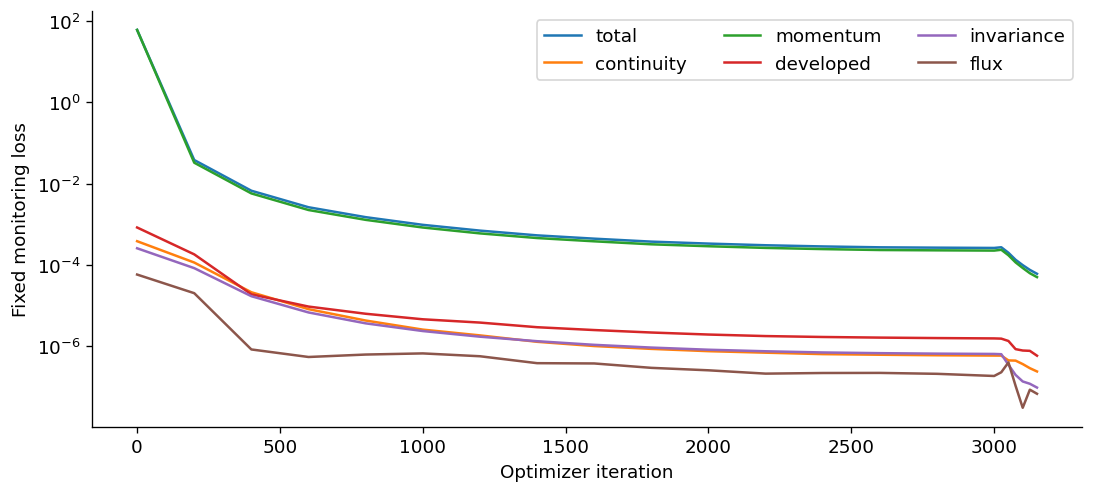

In [13]:
model = RectangularFlow().to(device=DEVICE, dtype=DTYPE)
if RESUME_CHECKPOINT is not None:
    model, _ = load_flow(RESUME_CHECKPOINT, DEVICE)
monitor = sample_inputs(512, np.random.default_rng(SEED+901))
history, best_score, best_state = [], float('inf'), None
started, optimizer_iterations = time.monotonic(), 0


def checkpoint(phase, iteration):
    global best_score, best_state
    model.eval()
    with torch.enable_grad(): terms = flow_terms(model, monitor)
    row = {key: float(val.detach().cpu()) for key, val in terms.items()}
    if not np.isfinite(list(row.values())).all():
        raise FloatingPointError('Non-finite independent monitor; previous checkpoint retained.')
    row.update(phase=phase, iteration=int(iteration), seconds=time.monotonic()-started)
    history.append(row)
    if row['total'] < best_score:
        best_score = row['total']
        best_state = {key: val.detach().cpu().clone() for key, val in model.state_dict().items()}
        torch.save(dict(config=CONFIG, model=best_state, monitor=row), RUN/'best_model.pt')
    (RUN/'training_history.json').write_text(json.dumps(history, indent=2))
    print(json.dumps(row), flush=True)


checkpoint('initial', 0)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, ADAM_STEPS, eta_min=2e-5)
for step in range(1, ADAM_STEPS+1):
    if HOURS is not None and time.monotonic()-started >= HOURS*3600: break
    model.train()
    loss = flow_terms(model, sample_inputs(SAMPLES, rng))['total']
    if not torch.isfinite(loss): raise FloatingPointError('Non-finite training loss.')
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 10.)
    if not torch.isfinite(norm): raise FloatingPointError('Non-finite gradient.')
    optimizer.step(); scheduler.step()
    optimizer_iterations = step
    if step % CHECK_EVERY == 0: checkpoint('Adam', step)
checkpoint('Adam_final', optimizer_iterations)

# Fixed collocation set for deterministic L-BFGS line searches.
model.load_state_dict(best_state)
polish_batch = sample_inputs(LBFGS_SAMPLES, np.random.default_rng(SEED+1901))
polish = torch.optim.LBFGS(model.parameters(), lr=.7, max_iter=LBFGS_INNER,
                         history_size=30, line_search_fn='strong_wolfe')
for outer in range(LBFGS_ROUNDS):
    def closure():
        polish.zero_grad(set_to_none=True)
        loss = flow_terms(model, polish_batch)['total']
        if not torch.isfinite(loss): raise FloatingPointError('Non-finite L-BFGS loss.')
        loss.backward()
        return loss
    try:
        polish.step(closure)
        inner = int(polish.state[next(model.parameters())].get('n_iter', 0))
        checkpoint('LBFGS_'+str(outer+1), optimizer_iterations+inner)
    except (RuntimeError, FloatingPointError) as exc:
        print('L-BFGS stopped; restoring best finite checkpoint:', exc)
        break
model.load_state_dict(best_state)
model = model.cpu().eval()
(RUN/'training_complete.json').write_text(json.dumps(dict(
    adam_steps=optimizer_iterations, best_fixed_loss=best_score,
    elapsed_seconds=time.monotonic()-started,
    note='Completion is not an accuracy guarantee; inspect validation.json.'), indent=2))
fig, ax = plt.subplots(figsize=(9, 4), layout='constrained')
for name in ['total', 'continuity', 'momentum', 'developed', 'invariance', 'flux']:
    ax.semilogy([r['iteration'] for r in history],
                [max(r[name], 1e-18) for r in history], label=name)
ax.set(xlabel='Optimizer iteration', ylabel='Fixed monitoring loss')
ax.legend(ncol=3)
fig.savefig(RUN/'training_history.png', dpi=220)
plt.show()


## ۵. اعتبارسنجی مستقل در کل کانال و فضای کنترل
تمام ۶۴ گوشهٔ بازهٔ شش‌بعدی، مرکز و چند نمونهٔ تصادفی بررسی می‌شوند. خطای فشار و سرعت با پوازوی، خطای مرزی، شار و تغییر ناخواستهٔ میدان با کنترل‌ها گزارش می‌شود. این نمونه‌برداری آزمون عددی است و اثبات یکنواخت در تمام پیوستار پارامترها نیست.

{
  "passed": true,
  "cases": 81,
  "grid": [
    81,
    33
  ],
  "worst": {
    "velocity_relative_l2": 0.0010533384426765482,
    "pressure_relative_l2": 0.0013384841895079937,
    "transverse_max_abs": 0.0010157959768548608,
    "max_condition_velocity_delta": 0.0012412667274475098,
    "max_condition_pressure_delta_normalized": 0.0015301271341741085
  },
  "velocity_boundary_max_error": 2.086162567138672e-07,
  "flux_max_relative_error": 2.5259589798043436e-05,
  "thresholds": {
    "velocity_relative_l2": 0.002,
    "pressure_relative_l2": 0.005,
    "transverse_abs": 0.002,
    "conditioning_abs": 0.002
  },
  "reference": "Analytical plane Poiseuille solution; no interior reference samples in training",
  "cases_include": "All 64 corners of the six-dimensional control box, its midpoint, and random controls",
  "scope": "Finite validation samples, not a proof over the continuum"
}


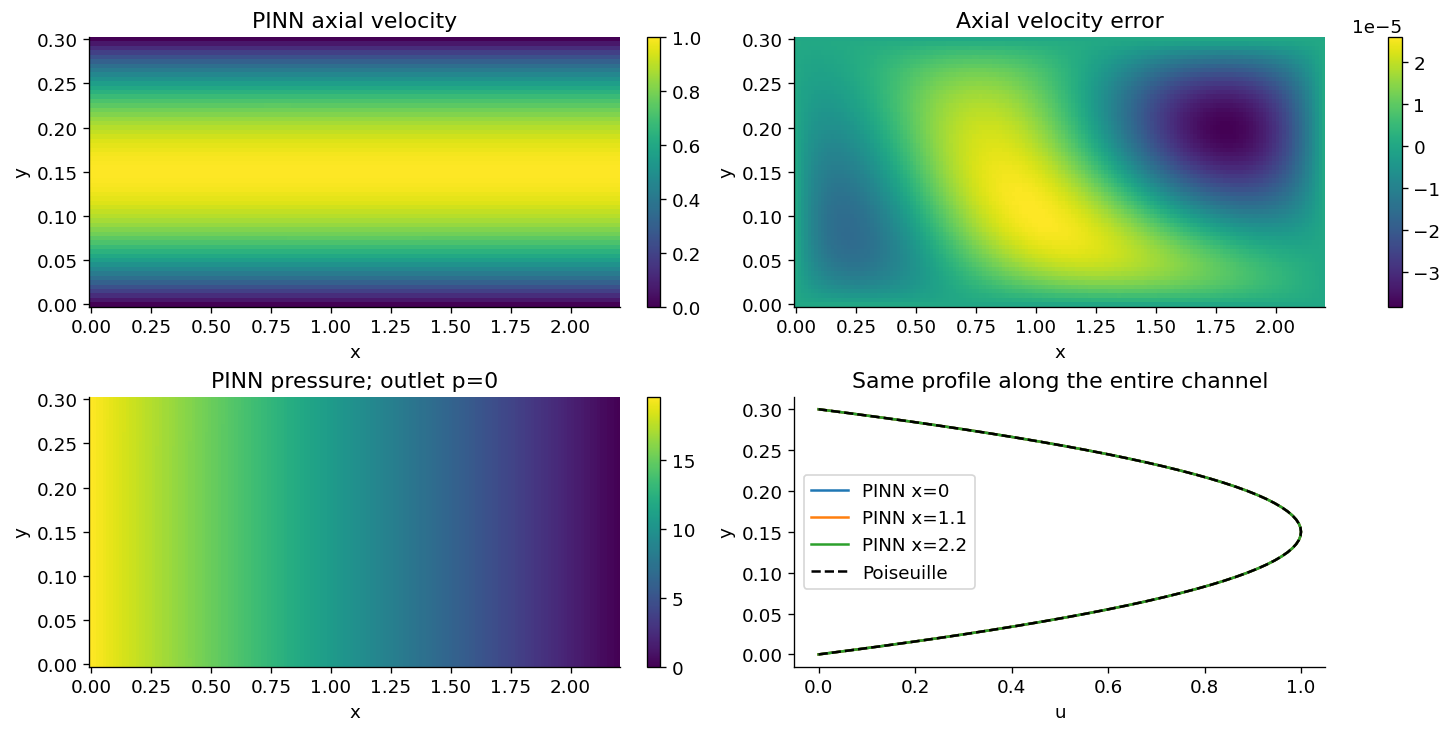

In [14]:
def validate_model(net, nx=81, ny=33, random_controls=16, save=True):
    x = np.linspace(0, L, nx); y = np.linspace(0, H, ny)
    X, Y = np.meshgrid(x, y)
    xy = np.column_stack((X.ravel(), Y.ravel()))
    ref = exact_flow(xy)
    corners = np.array(list(itertools.product([0., 1.], repeat=6)))
    bank = np.vstack((CONTROL_MID, CONTROL_BOUNDS[:, 0]+corners*CONTROL_SPAN,
                      CONTROL_BOUNDS[:, 0]+np.random.default_rng(SEED+82).random((random_controls, 6))*CONTROL_SPAN))
    baseline = evaluate_flow(net, xy, CONTROL_MID)
    rows = []
    for i, controls in enumerate(bank):
        pred = evaluate_flow(net, xy, controls)
        rows.append(dict(case=i, controls=controls.tolist(),
            velocity_relative_l2=float(np.linalg.norm(pred[:, :2]-ref[:, :2])/np.linalg.norm(ref[:, :2])),
            pressure_relative_l2=float(np.linalg.norm(pred[:, 2]-ref[:, 2])/np.linalg.norm(ref[:, 2])),
            transverse_max_abs=float(np.max(np.abs(pred[:, 1]))),
            max_condition_velocity_delta=float(np.max(np.abs(pred[:, :2]-baseline[:, :2]))),
            max_condition_pressure_delta_normalized=float(np.max(np.abs(pred[:, 2]-baseline[:, 2]))/PRESSURE_SCALE)))
    worst = {k: max(row[k] for row in rows) for k in rows[0] if k not in ['case', 'controls']}
    # Direct boundary and flux measurements, independent of the PDE residual.
    boundary_xy = np.vstack((np.column_stack((x, np.zeros(nx))),
                             np.column_stack((x, np.full(nx, H))),
                             np.column_stack((np.zeros(ny), y)),
                             np.column_stack((np.full(ny, L), y))))
    b = evaluate_flow(net, boundary_xy)
    boundary_error = float(np.max(np.abs(b[:, :2]-exact_flow(boundary_xy)[:, :2])))
    nodes, weights = np.polynomial.legendre.leggauss(32)
    flux_errors = []
    for sx in np.linspace(0, L, 11):
        uv = evaluate_flow(net, np.column_stack((np.full(32, sx), (nodes+1)*H/2)))
        flux_errors.append(abs(np.dot(uv[:, 0], weights)*H/2/(2*U_C*H/3)-1))
    passed = (worst['velocity_relative_l2'] <= VELOCITY_REL_TOL and
              worst['pressure_relative_l2'] <= PRESSURE_REL_TOL and
              worst['transverse_max_abs'] <= TRANSVERSE_ABS_TOL and
              worst['max_condition_velocity_delta'] <= CONDITIONING_ABS_TOL and
              worst['max_condition_pressure_delta_normalized'] <= CONDITIONING_ABS_TOL and
              max(flux_errors) <= VELOCITY_REL_TOL and boundary_error <= 1e-5)
    report = dict(passed=bool(passed), cases=len(bank), grid=[nx, ny], worst=worst,
        velocity_boundary_max_error=boundary_error, flux_max_relative_error=max(flux_errors),
        thresholds=dict(velocity_relative_l2=VELOCITY_REL_TOL, pressure_relative_l2=PRESSURE_REL_TOL,
                        transverse_abs=TRANSVERSE_ABS_TOL, conditioning_abs=CONDITIONING_ABS_TOL),
        reference='Analytical plane Poiseuille solution; no interior reference samples in training',
        cases_include='All 64 corners of the six-dimensional control box, its midpoint, and random controls',
        scope='Finite validation samples, not a proof over the continuum', details=rows)
    if save:
        (RUN/'validation.json').write_text(json.dumps(report, indent=2))
        np.savez_compressed(RUN/'flow_validation.npz', xy=xy, predicted=baseline,
                            reference=ref, control_bank=bank)
    return report


VALIDATION = validate_model(model)
print(json.dumps({k: v for k, v in VALIDATION.items() if k != 'details'}, indent=2))
x = np.linspace(0, L, 161); y = np.linspace(0, H, 61)
X, Y = np.meshgrid(x, y)
xy = np.column_stack((X.ravel(), Y.ravel()))
pred, ref = evaluate_flow(model, xy), exact_flow(xy)
fig, axes = plt.subplots(2, 2, figsize=(12, 6), layout='constrained')
for ax, values, title in [(axes[0, 0], pred[:, 0], 'PINN axial velocity'),
                          (axes[0, 1], pred[:, 0]-ref[:, 0], 'Axial velocity error'),
                          (axes[1, 0], pred[:, 2], 'PINN pressure; outlet p=0')]:
    im = ax.pcolormesh(X, Y, values.reshape(X.shape), shading='auto', cmap='viridis')
    fig.colorbar(im, ax=ax); ax.set(title=title, xlabel='x', ylabel='y')
for sx in [0, L/2, L]:
    profile = evaluate_flow(model, np.column_stack((np.full(len(y), sx), y)))
    axes[1, 1].plot(profile[:, 0], y, label=f'PINN x={sx:.2g}')
axes[1, 1].plot(4*U_C*(y/H)*(1-y/H), y, 'k--', label='Poiseuille')
axes[1, 1].set(xlabel='u', ylabel='y', title='Same profile along the entire channel')
axes[1, 1].legend()
fig.savefig(RUN/'flow_validation.png', dpi=220)
plt.show()


## ۶. رهاسازی از دیواره‌ها و حل مسیر ذرات

مرکز ذرهٔ پایین در `y=d/2+gap` و مرکز ذرهٔ بالا در `y=H-d/2-gap` قرار می‌گیرد تا برخورد مصنوعی در زمان صفر ایجاد نشود. مختصات `x` نازل همچنان از `0` تا `L` آزاد است. دیوارهٔ فیزیکی جابه‌جا نشده است.

$$\dot{\mathbf{x}}_p=\mathbf{v}_p,\qquad
\dot{\mathbf{v}}_p=\frac{18 f(Re_p)}{(\rho_p/\rho_f)Re\,d^2}(\mathbf{u}-\mathbf{v}_p),
\quad Re_p=Re\,d\,|\mathbf{u}-\mathbf{v}_p|.$$

برای استوکس `f=1` و برای شیلر–نومان `f=1+0.15 Re_p^0.687` زیر `1000` است. سرعت اولیه بازنویسی نمی‌شود. تماس با دیواره، خروج از ورودی و رسیدن مرکز به خروجی رویداد پایانی‌اند. در سرهای باز، ملاک خروج مرکز ذره است. پرتاب از `x=L` با سرعت رو به بیرون ممکن است فوراً به خروج منجر شود؛ پوشش کامل بازه به معنی قابل‌استفاده بودن تمام حالت‌ها برای هر هدف نیست.


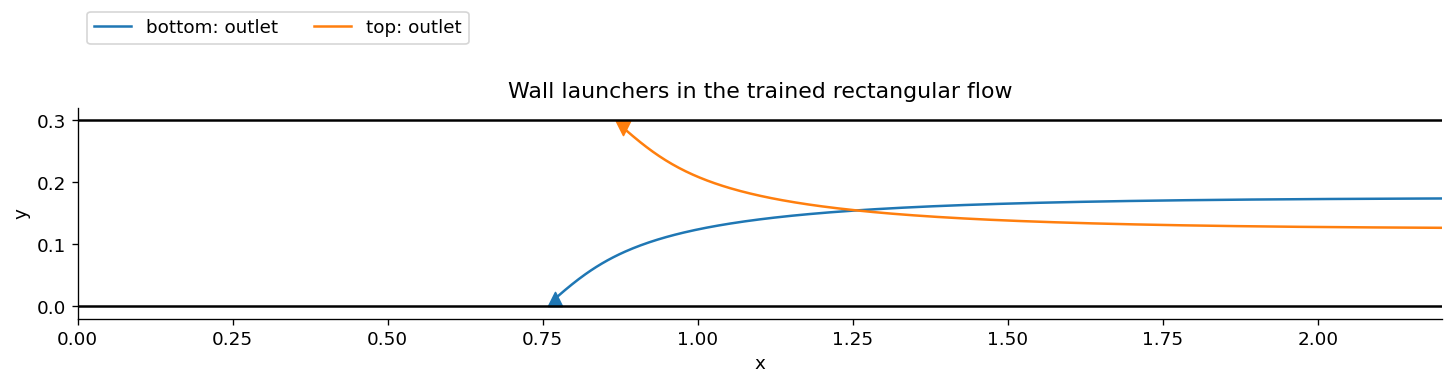

bottom outlet age: 1.6984636772426098
top outlet age: 1.5855386656996453


In [15]:
def check_controls(controls):
    c = np.asarray(controls, float)
    if c.shape != (6,) or not np.isfinite(c).all():
        raise ValueError('Each experiment needs exactly six finite, SHARED launcher controls.')
    if np.any(c < CONTROL_BOUNDS[:, 0]-1e-12) or np.any(c > CONTROL_BOUNDS[:, 1]+1e-12):
        raise ValueError('Launcher controls are outside the trained box.')
    return np.clip(c, CONTROL_BOUNDS[:, 0], CONTROL_BOUNDS[:, 1])


def particle_acceleration(fluid, particle_velocity):
    slip = np.asarray(fluid)-np.asarray(particle_velocity)
    rep = RE*DIAMETER*np.linalg.norm(slip)
    factor = 1.0
    if DRAG_LAW == 'schiller-naumann':
        factor = 1+.15*rep**.687 if rep < 1000 else .44*rep/24
    return 18*factor*slip/(DENSITY_RATIO*RE*DIAMETER**2)


class ParticlePath:
    def __init__(self, solution, side, controls, status):
        self.sol, self.side = solution, side
        self.controls, self.status = controls.copy(), status
        self.end = float(solution.t[-1])
        self.ok = bool(solution.success and np.isfinite(solution.y).all())

    def state(self, ages, strict=True):
        a = np.atleast_1d(np.asarray(ages, float))
        if strict and (np.any(a < -1e-9) or np.any(a > self.end+1e-8)):
            raise ValueError('Requested a particle state outside its physical trajectory.')
        return self.sol.sol(np.clip(a, 0, self.end)).T


def trace_particle(field, controls, side, tmax=TRAJECTORY_TMAX,
                   rtol=ODE_RTOL, atol=ODE_ATOL, max_step=TRAJECTORY_MAX_STEP):
    """field(xy, shared_controls) -> Nx2 or Nx3; no particle feedback to fluid."""
    c = check_controls(controls)
    if side not in (0, 1): raise ValueError('side=0 is bottom, side=1 is top.')
    j = 0 if side == 0 else 3
    y0 = DIAMETER/2+LAUNCH_GAP if side == 0 else H-DIAMETER/2-LAUNCH_GAP
    initial = [c[j], y0, c[j+1], c[j+2]]
    calls = 0
    def rhs(t, state):
        nonlocal calls
        calls += 1
        if calls > 100000: raise RuntimeError('ODE RHS budget exhausted.')
        # Event-bracketing stages can leave the domain. Query the nearest boundary;
        # never treat a neural extrapolation outside the rectangle as a solution.
        xy = np.clip(state[:2], [0, 0], [L, H])[None, :]
        fluid = np.asarray(field(xy, c))[0, :2]
        if not np.isfinite(fluid).all(): raise FloatingPointError('Non-finite fluid velocity.')
        acc = particle_acceleration(fluid, state[2:])
        return [state[2], state[3], acc[0], acc[1]]
    def lower(t, z): return z[1]-DIAMETER/2
    def upper(t, z): return H-DIAMETER/2-z[1]
    def inlet(t, z): return z[0]
    def outlet(t, z): return L-z[0]
    events = [lower, upper, inlet, outlet]
    for event in events: event.terminal, event.direction = True, -1
    tau = DENSITY_RATIO*RE*DIAMETER**2/18
    # Implicit integration avoids stiffness when users lower density or diameter.
    method = 'Radau' if tau < max_step/3 else 'RK45'
    solution = solve_ivp(rhs, (0, tmax), initial, events=events, dense_output=True,
        method=method, rtol=rtol, atol=atol, max_step=max_step)
    hit = next((i for i, values in enumerate(solution.t_events) if len(values)), None)
    status = (['lower_wall', 'upper_wall', 'inlet_exit', 'outlet'][hit] if hit is not None
              else 'time_limit' if solution.success else 'solver_failed')
    return ParticlePath(solution, side, c, status)


def direct_field(xy, controls): return evaluate_flow(model, xy, controls)[:, :2]


class FlowLookup:
    """2D speed table at midpoint controls; final verification uses all 8 inputs.

    This reduction is valid for the specified one-way fully developed flow only.
    Conditional drift is measured before optimization; the table is not a new MLP.
    """
    def __init__(self, net, nx=241, ny=121):
        self.x, self.y = np.linspace(0, L, nx), np.linspace(0, H, ny)
        X, Y = np.meshgrid(self.x, self.y, indexing='ij')
        xy = np.column_stack((X.ravel(), Y.ravel()))
        values = evaluate_flow(net, xy, CONTROL_MID)[:, :2].reshape(nx, ny, 2)
        self.interpolate = RegularGridInterpolator((self.x, self.y), values,
                                                   bounds_error=True)
        self.values = values
    def __call__(self, xy, controls=None):
        return self.interpolate(np.clip(np.atleast_2d(xy), [0, 0], [L, H]))


# Two launches use the SAME six-control tuple, with wall-normal signs preserved.
EXAMPLE_CONTROLS = CONTROL_MID.copy()
EXAMPLE_CONTROLS[[0, 3]] = [.35*L, .40*L]
EXAMPLE_CONTROLS[[1, 4]] = [.55, .55]
EXAMPLE_CONTROLS[[2, 5]] = [.48, -.48]
example_paths = [trace_particle(direct_field, EXAMPLE_CONTROLS, side) for side in (0, 1)]
fig, ax = plt.subplots(figsize=(12, 3), layout='constrained')
for p in example_paths:
    xy = p.state(np.linspace(0, p.end, 400))[:, :2]
    ax.plot(xy[:, 0], xy[:, 1], label=f'{["bottom", "top"][p.side]}: {p.status}')
    ax.scatter(xy[0, 0], xy[0, 1], marker='^' if p.side == 0 else 'v', s=70)
ax.axhline(0, color='k'); ax.axhline(H, color='k')
ax.set(xlim=(0, L), ylim=(-.02, H+.02), xlabel='x', ylabel='y',
       title='Wall launchers in the trained rectangular flow', aspect='equal')
ax.legend(loc='upper left', bbox_to_anchor=(0, 1.5), ncol=2)
fig.savefig(RUN/'wall_launcher_examples.png', dpi=220)
plt.show()
for p in example_paths: print(['bottom', 'top'][p.side], p.status, 'age:', p.end)


## ۷. نمایشگر مستقل کنترل دو پرتابگر
فایل HTML تولیدشده بدون سرور باز می‌شود. شش اسلایدر و کشیدن از دیواره برای تعیین موقعیت و سرعت دارد. مسیر نمایشگر از جدول میدان PINN و RK4 استفاده می‌کند؛ معیار پذیرش علمی، حل مستقیم SciPy در بخش بهینه‌سازی است.

In [16]:
# A standalone offline viewer. It uses a sampled PINN velocity table and RK4;
# scientific formation acceptance uses SciPy ODE + direct PINN, not this viewer.
def write_viewer(net, filename):
    table = FlowLookup(net, nx=181, ny=91)
    payload = dict(L=L, H=H, re=RE, diameter=DIAMETER, density=DENSITY_RATIO,
        gap=LAUNCH_GAP, drag=DRAG_LAW, bounds=CONTROL_BOUNDS.tolist(),
        names=list(CONTROL_NAMES), controls=EXAMPLE_CONTROLS.tolist(),
        nx=len(table.x), ny=len(table.y), values=table.values.tolist(),
        validation_passed=bool(VALIDATION['passed']))
    template = r'''<!doctype html><html lang="en"><meta charset="utf-8">
<title>Two wall launchers · rectangular Poiseuille flow</title>
<style>body{font:15px system-ui;background:#101b2d;color:#e7edf8;margin:25px auto;max-width:1150px;padding:16px}
h1{font-size:23px}canvas{width:100%;background:#edf6fc;border-radius:12px}label{display:grid;grid-template-columns:100px 1fr 65px;gap:12px;align-items:center}
.controls{display:grid;grid-template-columns:1fr 1fr;gap:10px 35px;margin:22px 0}button{padding:10px 20px;margin:10px 5px 15px 0;border:0;border-radius:8px;background:#6ee7cf;color:#101b2d;font-weight:700}small{color:#b9c8dd}</style>
<h1>Rectangular channel · bottom and top wall launchers</h1>
<p>Adjust six shared launch controls. Drag from a wall to change launch position and velocity.</p>
<div class="controls" id="controls"></div>
<button id="run">Trace both paths</button><button id="reset">Reset</button>
<canvas id="c" width="1400" height="420"></canvas>
<p id="status"></p><small>Offline PINN lookup + RK4 preview. The fluid is independent of launch settings in one-way coupling.
This viewer does not certify an optimized formation; use the direct-PINN validation outputs.</small>
<script>const D=__PAYLOAD__;let controls=D.controls.slice(), paths=[], drag=null;
const c=document.getElementById('c'),ctx=c.getContext('2d'),margin=50,scale=(c.width-2*margin)/D.L;
const originY=(c.height+D.H*scale)/2;
function screen(x,y){return [margin+x*scale,originY-y*scale]}
function field(x,y){let fx=Math.max(0,Math.min(D.nx-1-1e-9,x/D.L*(D.nx-1))),fy=Math.max(0,Math.min(D.ny-1-1e-9,y/D.H*(D.ny-1)));
let i=Math.floor(fx),j=Math.floor(fy),a=fx-i,b=fy-j;return [0,1].map(k=>(1-a)*(1-b)*D.values[i][j][k]+a*(1-b)*D.values[i+1][j][k]+(1-a)*b*D.values[i][j+1][k]+a*b*D.values[i+1][j+1][k])}
function rhs(z){let f=field(z[0],z[1]),du=f[0]-z[2],dv=f[1]-z[3],rep=D.re*D.diameter*Math.hypot(du,dv),fac=D.drag==='stokes'?1:(rep<1000?1+.15*Math.pow(rep,.687):.44*rep/24),k=18*fac/(D.density*D.re*D.diameter**2);return [z[2],z[3],k*du,k*dv]}
function integrate(side){let k=side*3,z=[controls[k],side?D.H-D.diameter/2-D.gap:D.diameter/2+D.gap,controls[k+1],controls[k+2]],a=[z.slice()],tau=D.density*D.re*D.diameter**2/18;
let dt=Math.min(.004,tau/8),steps=Math.min(150000,Math.ceil(20/dt));
for(let n=0;n<steps;n++){let p=rhs(z),q=rhs(z.map((v,i)=>v+dt*p[i]/2)),r=rhs(z.map((v,i)=>v+dt*q[i]/2)),s=rhs(z.map((v,i)=>v+dt*r[i]));z=z.map((v,i)=>v+dt*(p[i]+2*q[i]+2*r[i]+s[i])/6);
if(!z.every(Number.isFinite)||z[0]<0||z[0]>D.L||z[1]<D.diameter/2||z[1]>D.H-D.diameter/2)break;if(n%3===0)a.push(z.slice())}return a}
function draw(){ctx.clearRect(0,0,c.width,c.height);ctx.fillStyle='#d9eaf5';let p=screen(0,D.H);ctx.fillRect(p[0],p[1],D.L*scale,D.H*scale);
ctx.strokeStyle='#294663';ctx.lineWidth=4;for(let y of [0,D.H]){let a=screen(0,y),b=screen(D.L,y);ctx.beginPath();ctx.moveTo(...a);ctx.lineTo(...b);ctx.stroke()}
for(let s=0;s<2;s++){ctx.strokeStyle=s?'#d64c70':'#067e9c';ctx.lineWidth=3;ctx.beginPath();paths[s].forEach((z,i)=>{let p=screen(z[0],z[1]);i?ctx.lineTo(...p):ctx.moveTo(...p)});ctx.stroke();let p=screen(controls[3*s],s?D.H:0);ctx.fillStyle=ctx.strokeStyle;ctx.beginPath();ctx.arc(...p,8,0,2*Math.PI);ctx.fill();ctx.beginPath();ctx.moveTo(...p);ctx.lineTo(p[0]+controls[3*s+1]*50,p[1]-controls[3*s+2]*50);ctx.stroke()}
ctx.fillStyle='#294663';ctx.font='19px system-ui';ctx.fillText('inlet: parabolic profile',margin,45);ctx.fillText('outlet',c.width-130,45)}
function update(){document.querySelectorAll('input').forEach((e,i)=>{e.value=controls[i];e.nextElementSibling.textContent=controls[i].toFixed(3)});paths=[integrate(0),integrate(1)];draw();document.getElementById('status').textContent='Saved flow validation: '+(D.validation_passed?'PASS':'FAIL — preview only')}
D.names.forEach((name,i)=>{let label=document.createElement('label');label.innerHTML=`<span>${name}</span><input type="range" min="${D.bounds[i][0]}" max="${D.bounds[i][1]}" step="${(D.bounds[i][1]-D.bounds[i][0])/1000}"><output></output>`;label.querySelector('input').oninput=e=>{controls[i]=+e.target.value;update()};document.getElementById('controls').appendChild(label)});
document.getElementById('run').onclick=update;document.getElementById('reset').onclick=()=>{controls=D.controls.slice();update()};
function point(e){let b=c.getBoundingClientRect();return [(e.clientX-b.left)*c.width/b.width,(e.clientY-b.top)*c.height/b.height]}
c.onpointerdown=e=>{let [sx,sy]=point(e),y=(originY-sy)/scale;drag=y>D.H/2?1:0;c.setPointerCapture(e.pointerId);controls[3*drag]=Math.max(0,Math.min(D.L,(sx-margin)/scale));update()};
c.onpointerup=e=>{if(drag===null)return;let [sx,sy]=point(e),p=screen(controls[3*drag],drag?D.H:0);for(let j=1;j<=2;j++){let val=j===1?(sx-p[0])/50:(p[1]-sy)/50;controls[3*drag+j]=Math.max(D.bounds[3*drag+j][0],Math.min(D.bounds[3*drag+j][1],val))}drag=null;update()};update();</script></html>'''
    filename.write_text(template.replace('__PAYLOAD__', json.dumps(payload)), encoding='utf-8')
    return filename


VIEWER_PATH = write_viewer(model, RUN/'wall_launchers_viewer.html')
display(FileLink(str(VIEWER_PATH)))
# Download and open the HTML in a browser; no server or internet is needed.


/kaggle/working/rectangular_wall_launchers_1793531860808680981/wall_launchers_viewer.html

## ۸. طراحی آزمایش‌های شکل نزدیک خروجی

آزمایش‌ها: مثلث، مربع، دایرهٔ ۱۰ ذره‌ای، S با ۸ ذره و پیکان با ۷ ذره. مرکز هدف نزدیک خروجی اما **داخل کانال** قرار دارد؛ روی خط `x=L` فقط آرایش یک‌بعدی ممکن است. هیچ ناحیهٔ اضافه‌ای بعد از خروجی ساخته نشده است.

در هر آزمایش متغیرها عبارت‌اند از شش کنترل **مشترک** پرتابگرها، انتخاب یکی از دو پرتابگر برای هر ذره و سن آن ذره در لحظهٔ هدف. اگر سن‌ها $a_i$ باشند، زمان مشترک $T=\max_i a_i+\text{lead}$ و زمان رهاسازی $t_i=T-a_i$ است. پس زمان رهاسازی یک تصمیم کنترل است، نه ورودی جدید شبکه. تزریق‌های کاملاً هم‌زمان الزام نشده‌اند.

فقط دو منحنی مسیر متفاوت برای هر تنظیم وجود دارد؛ ذرات هر پرتابگر روی یک منحنی با تأخیرهای مختلف حرکت می‌کنند. بنابراین هر شکل دلخواه لزوماً دست‌یافتنی نیست. اگر شکل به تلرانس نرسد یا برخورد داشته باشد، بهترین نتیجه با `success=False` و خطای واقعی ذخیره می‌شود. این یک آزمون دست‌یافتنی بودن با جست‌وجوی محدود است، نه تضمین جواب یا اثبات ناممکن بودن. شکل، یک تصویر در یک لحظه است و ثابت‌ماندن آن در ادامه ادعا نمی‌شود.


In [17]:
# A formation is a simultaneous snapshot in a region just BEFORE the outlet.
# A 2D shape cannot lie on the single line x=L. No artificial extension is added.
SHAPES = ['triangle', 'square', 'circle_10', 's_8', 'chevron_7']
TARGET_CENTER = np.array([0.86*L, H/2])
TARGET_RADIUS = 0.075
S_WIDTH, S_HEIGHT = 0.13, 0.19
POSITION_TOLERANCE = 0.003
COLLISION_MARGIN = 0.001
LEAD_TIME = 0.25
SCOUT_POWER, OPT_STARTS = 6, 3  # 2**6 shared six-control samples + anchors.
COARSE_MAX_NFEV, DIRECT_MAX_NFEV = 70, 15
COLLISION_SAMPLES = 25
PAIR_VERIFY_SAMPLES = 501
REFERENCE_TOLERANCE = 0.004
RUN_OPTIMIZATION = True

assert np.isfinite(TARGET_CENTER).all() and min(TARGET_RADIUS, S_WIDTH, S_HEIGHT,
    POSITION_TOLERANCE, COLLISION_MARGIN, LEAD_TIME, REFERENCE_TOLERANCE) > 0
assert 1 <= SCOUT_POWER <= 12 and min(OPT_STARTS, COARSE_MAX_NFEV, DIRECT_MAX_NFEV) >= 1
assert COLLISION_SAMPLES >= 3 and PAIR_VERIFY_SAMPLES >= 21
OPT_CONFIG = dict(shapes=SHAPES, center=TARGET_CENTER.tolist(), radius=TARGET_RADIUS,
    s_width=S_WIDTH, s_height=S_HEIGHT, position_tolerance=POSITION_TOLERANCE,
    collision_margin=COLLISION_MARGIN, lead_time=LEAD_TIME,
    scout_power=SCOUT_POWER, starts=OPT_STARTS, coarse_max_nfev=COARSE_MAX_NFEV,
    direct_max_nfev=DIRECT_MAX_NFEV, collision_samples=COLLISION_SAMPLES,
    reference_tolerance=REFERENCE_TOLERANCE,
    shared_controls='six numbers for the WHOLE shape; no per-particle launch position or speed',
    extra_decisions='launcher identity and emission time per particle; neither is a flow-network input')
(RUN/'optimization_config.json').write_text(json.dumps(OPT_CONFIG, indent=2))


634

## ۹. جست‌وجوی چندشروعی و بررسی مستقیم
بانک سوبول شش‌بعدی و چند حالت لنگر برای شروع جست‌وجو ساخته می‌شود. جدول میدان دوبعدی در مرکز کنترل‌ها جست‌وجو را سریع می‌کند؛ این کاهش فقط به دلیل استقلال فیزیکی جریان از پرتابگرها مجاز است. سپس کنترل‌های منتخب با شبکهٔ کامل هشت‌ورودی بازبینی و اصلاح می‌شوند. همان شش کنترل و زمان‌ها با ODE دقیق‌تر و با میدان تحلیلی دوباره آزمون می‌شوند. برچسب PASS علاوه بر خطای هدف، به اعتبار میدان و فاصلهٔ ذرات بستگی دارد. بررسی فاصله عددی است؛ نیروی تماس یا تصحیح مسیر پس از برخورد مدل نشده است.

In [18]:
from collections import OrderedDict


def target_points(kind):
    if kind in ['triangle', 'square'] or kind.startswith('circle_'):
        n = 3 if kind == 'triangle' else 4 if kind == 'square' else int(kind.split('_')[1])
        if not 3 <= n <= 40: raise ValueError('Polygon count must be 3..40.')
        phase = np.pi/4 if kind == 'square' else np.pi/2
        a = phase+np.arange(n)*2*np.pi/n
        pts = TARGET_CENTER+TARGET_RADIUS*np.column_stack((np.cos(a), np.sin(a)))
        closed = True
    elif kind.startswith('s_'):
        n = int(kind.split('_')[1]); t = np.linspace(0, 1, 2001)
        curve = np.column_stack((S_WIDTH/2*np.sin(2*np.pi*t), S_HEIGHT*(.5-t)))
        # Equal arclength spacing avoids visually uneven point density.
        arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))]
        knots = np.linspace(0, arc[-1], n)
        pts = TARGET_CENTER+np.column_stack([np.interp(knots, arc, curve[:, j]) for j in (0, 1)])
        closed = False
    elif kind.startswith('chevron_'):
        n = int(kind.split('_')[1]); t = np.linspace(-1, 1, n)
        pts = TARGET_CENTER+np.column_stack((TARGET_RADIUS*(1-2*np.abs(t)), TARGET_RADIUS*t))
        closed = False
    else: raise ValueError('Use triangle, square, circle_N, s_N or chevron_N.')
    if not 3 <= len(pts) <= 40: raise ValueError('Use 3..40 particles.')
    radius = DIAMETER/2
    if np.any(pts <= [radius, radius]) or np.any(pts >= [L-radius, H-radius]):
        raise ValueError(f'{kind}: target does not fit inside the rectangle with radius clearance.')
    distances = np.linalg.norm(pts[:, None]-pts[None, :], axis=2)
    np.fill_diagonal(distances, np.inf)
    if distances.min() < DIAMETER+COLLISION_MARGIN:
        raise ValueError(f'{kind}: target points overlap at the configured diameter.')
    return pts, closed


class SharedLauncherPlanner:
    def __init__(self, field, label, rtol=2e-6, atol=2e-8, max_step=.06):
        self.field, self.label = field, label
        self.rtol, self.atol, self.max_step = rtol, atol, max_step
        self.cache, self.calls = OrderedDict(), 0

    def physical(self, z):
        return CONTROL_BOUNDS[:, 0]+np.clip(np.asarray(z)[:6], 0, 1)*CONTROL_SPAN

    def paths(self, z):
        key = tuple(np.round(np.asarray(z)[:6], 12))
        if key in self.cache:
            self.cache.move_to_end(key)
            return self.cache[key]
        c = self.physical(z)
        pair = [trace_particle(self.field, c, side, rtol=self.rtol,
                 atol=self.atol, max_step=self.max_step) for side in (0, 1)]
        if not all(p.ok for p in pair): raise RuntimeError('Trajectory integration failed.')
        self.calls += 2
        self.cache[key] = pair
        if len(self.cache) > 32: self.cache.popitem(last=False)
        return pair

    def endpoints(self, z, assignment):
        pair = self.paths(z)
        ages = np.array([np.clip(z[6+i], 0, 1)*pair[s].end
                         for i, s in enumerate(assignment)])
        actual = np.array([pair[s].state([ages[i]])[0, :2] for i, s in enumerate(assignment)])
        return pair, ages, actual

    def residual(self, z, assignment, targets):
        pair, ages, actual = self.endpoints(z, assignment)
        residual = list(((actual-targets)/H).ravel())
        # Pair checks cover the interval in which BOTH particles exist, up to
        # the target instant. Shared-time samples expressed backwards from T.
        for i in range(len(assignment)):
            for j in range(i):
                backwards = np.linspace(0, min(ages[i], ages[j]), COLLISION_SAMPLES)
                pi = pair[assignment[i]].state(ages[i]-backwards)[:, :2]
                pj = pair[assignment[j]].state(ages[j]-backwards)[:, :2]
                distance = np.linalg.norm(pi-pj, axis=1)
                residual.extend((2*np.maximum(0, DIAMETER+COLLISION_MARGIN-distance)/H).tolist())
        return np.asarray(residual)

    def refine(self, z, assignment, targets, max_nfev):
        z = np.clip(np.asarray(z, float), 0, 1)
        # Absolute finite differences remain meaningful for near-zero controls.
        def jacobian(point):
            base = self.residual(point, assignment, targets)
            jac = np.empty((len(base), len(point)))
            for j in range(len(point)):
                delta = .002 if j < 6 else .0002
                delta = delta if point[j]+delta <= 1 else -delta
                trial = point.copy(); trial[j] += delta
                jac[:, j] = (self.residual(trial, assignment, targets)-base)/delta
            return jac
        result = least_squares(lambda point: self.residual(point, assignment, targets),
            z, jac=jacobian, bounds=(np.zeros(len(z)), np.ones(len(z))),
            max_nfev=max_nfev, ftol=2e-6, xtol=2e-6, gtol=2e-6)
        return result.x, dict(message=result.message, nfev=int(result.nfev),
            cost=float(result.cost), optimizer_terminated=bool(result.success))


def scout_bank(planner):
    samples = qmc.Sobol(6, scramble=True, seed=SEED+111).random_base2(SCOUT_POWER)
    anchors = []
    for xb in [.55, .72, .84]:
        for speed in [.35, .7, 1.0]:
            c = CONTROL_MID.copy(); c[[0, 3]] = [xb*L, xb*L]
            c[[1, 4]] = [.5, .5]; c[[2, 5]] = [speed, -speed]
            anchors.append((c-CONTROL_BOUNDS[:, 0])/CONTROL_SPAN)
    samples = np.vstack((samples, anchors))
    bank = []
    for i, z in enumerate(samples):
        try:
            paths = planner.paths(z)
            if min(p.end for p in paths) > .02:
                ages = [np.linspace(0, p.end, 301) for p in paths]
                points = [p.state(a)[:, :2] for p, a in zip(paths, ages)]
                bank.append((z, paths, ages, points))
        except (RuntimeError, FloatingPointError, ValueError) as exc:
            print('Scout skipped:', i, str(exc))
        if (i+1) % 16 == 0:
            print(f'Scout {i+1}/{len(samples)}: {len(bank)} usable two-launcher cases', flush=True)
    if not bank: raise RuntimeError('No valid two-launcher search paths found.')
    return bank


def seeds_for_shape(bank, targets):
    ranked = []
    for controls, paths, ages, points in bank:
        distance = np.array([np.linalg.norm(p[None, :, :]-targets[:, None, :], axis=2)
                             for p in points])
        index = distance.argmin(axis=2)
        best = np.take_along_axis(distance, index[:, :, None], axis=2)[:, :, 0]
        assignment = best.argmin(axis=0)
        # Use both physical launchers in every experiment. Also explore a
        # fixed lower/upper assignment to avoid one discrete search choice.
        alternatives = [assignment, (targets[:, 1] > H/2).astype(int)]
        for assign in alternatives:
            assign = assign.copy()
            if len(np.unique(assign)) == 1:
                old = int(assign[0]); new = 1-old
                k = np.argmin(best[new]-best[old]); assign[k] = new
            fractions = np.array([ages[s][index[s, i]]/paths[s].end for i, s in enumerate(assign)])
            score = float(np.mean([best[s, i]**2 for i, s in enumerate(assign)]))
            ranked.append((score, np.r_[controls, fractions], assign))
    ranked.sort(key=lambda r: r[0])
    chosen = []
    for item in ranked:
        if all(np.linalg.norm(item[1][:6]-old[1][:6]) > .08 or
               not np.array_equal(item[2], old[2]) for old in chosen):
            chosen.append(item)
        if len(chosen) == OPT_STARTS: break
    return chosen


def minimum_separation(pair, assignment, ages, samples=PAIR_VERIFY_SAMPLES, refine=True):
    minimum = float('inf')
    for i in range(len(assignment)):
        for j in range(i):
            end = min(ages[i], ages[j])
            def distance(backwards):
                backwards = np.atleast_1d(backwards)
                a = pair[assignment[i]].state(ages[i]-backwards)[:, :2]
                b = pair[assignment[j]].state(ages[j]-backwards)[:, :2]
                return np.linalg.norm(a-b, axis=1)
            times = np.linspace(0, end, samples)
            d = distance(times); minimum = min(minimum, float(d.min()))
            if refine and end > 0:
                local = np.flatnonzero((d[1:-1] <= d[:-2]) & (d[1:-1] <= d[2:]))+1
                for k in local:
                    r = minimize_scalar(lambda t: float(distance(t)[0]),
                        bounds=(times[k-1], times[k+1]), method='bounded', options={'xatol': 1e-9})
                    minimum = min(minimum, float(r.fun))
    return minimum


def make_candidate(planner, z, assignment, targets, diagnostics):
    pair, ages, actual = planner.endpoints(z, assignment)
    errors = np.linalg.norm(actual-targets, axis=1)
    sep = minimum_separation(pair, assignment, ages)
    score = (max(0, float(errors.max())-POSITION_TOLERANCE)/H +
             2*max(0, DIAMETER+COLLISION_MARGIN-sep)/H)
    return dict(z=z, assignment=assignment.copy(), pair=pair, ages=ages, actual=actual,
        errors=errors, separation=sep, score=score, diagnostics=diagnostics)


def plan_formation(kind, coarse, direct, bank):
    targets, closed = target_points(kind)
    candidates, logs = [], []
    for i, (_, initial, assignment) in enumerate(seeds_for_shape(bank, targets)):
        try:
            z, diag = coarse.refine(initial, assignment, targets, COARSE_MAX_NFEV)
            candidate = make_candidate(coarse, z, assignment, targets, diag)
            candidates.append(candidate)
            print(f'{kind} start {i+1}: lookup max error={candidate["errors"].max():.5g}, '
                  f'min separation={candidate["separation"]:.5g}', flush=True)
        except (RuntimeError, FloatingPointError, ValueError) as exc:
            logs.append(dict(stage='lookup', start=i+1, error=str(exc)))
    if not candidates:
        return dict(kind=kind, success=False, reason='All local searches failed.', failures=logs)
    candidates.sort(key=lambda r: (r['score'], float(r['errors'].max())))
    # Verify/refine the best coarse candidates with the actual frozen 8-input net.
    verified = []
    for candidate in candidates[:min(2, len(candidates))]:
        try:
            base = make_candidate(direct, candidate['z'], candidate['assignment'], targets,
                                  dict(stage='direct_before_refinement'))
            verified.append(base)
            z, diag = direct.refine(candidate['z'], candidate['assignment'], targets, DIRECT_MAX_NFEV)
            verified.append(make_candidate(direct, z, candidate['assignment'], targets, diag))
        except (RuntimeError, FloatingPointError, ValueError) as exc:
            logs.append(dict(stage='direct', error=str(exc)))
    if not verified:
        return dict(kind=kind, success=False, reason='Direct PINN verification failed.', failures=logs)
    verified.sort(key=lambda r: (r['score'], float(r['errors'].max())))
    selected = verified[0]
    c = direct.physical(selected['z'])
    assignment, ages = selected['assignment'], selected['ages']
    # Reintegrate at stricter ODE tolerances, using EXACTLY the same six controls
    # and the same release schedule. No hidden retiming or per-particle control.
    strict_pair = [trace_particle(direct.field, c, s, rtol=2e-9, atol=2e-11,
                                  max_step=TRAJECTORY_MAX_STEP/2) for s in (0, 1)]
    exact_pair = [trace_particle(exact_flow, c, s, rtol=2e-10, atol=2e-12,
                                 max_step=TRAJECTORY_MAX_STEP/2) for s in (0, 1)]
    strict_valid = all(strict_pair[s].ok and ages[i] <= strict_pair[s].end+1e-8
                       for i, s in enumerate(assignment))
    reference_valid = all(exact_pair[s].ok and ages[i] <= exact_pair[s].end+1e-8
                          for i, s in enumerate(assignment))
    actual = np.array([strict_pair[s].state([ages[i]], strict=False)[0, :2]
                       for i, s in enumerate(assignment)])
    reference = np.array([exact_pair[s].state([ages[i]], strict=False)[0, :2]
                          for i, s in enumerate(assignment)])
    errors = np.linalg.norm(actual-targets, axis=1)
    ref_errors = np.linalg.norm(reference-targets, axis=1)
    delta = np.linalg.norm(reference-actual, axis=1)
    sep = minimum_separation(strict_pair, assignment, ages) if strict_valid else 0.
    ref_sep = minimum_separation(exact_pair, assignment, ages) if reference_valid else 0.
    T = float(ages.max()+LEAD_TIME)
    release = T-ages
    position_ok = bool(strict_valid and errors.max() <= POSITION_TOLERANCE)
    clearance_ok = bool(strict_valid and sep >= DIAMETER+COLLISION_MARGIN)
    reference_ok = bool(reference_valid and ref_errors.max() <= REFERENCE_TOLERANCE and
                        delta.max() <= REFERENCE_TOLERANCE and ref_sep >= DIAMETER+COLLISION_MARGIN)
    quality_ok = bool(VALIDATION['passed'])
    success = bool(position_ok and clearance_ok and reference_ok and quality_ok)
    schedule, trajectories = [], []
    for i, side in enumerate(assignment):
        j = 3*side
        schedule.append(dict(particle=i+1, launcher=['bottom', 'top'][side],
            x_launch=float(c[j]), u_launch=float(c[j+1]), v_launch=float(c[j+2]),
            release_time=float(release[i]), age_at_target=float(ages[i]),
            target_x=float(targets[i, 0]), target_y=float(targets[i, 1]),
            actual_x=float(actual[i, 0]), actual_y=float(actual[i, 1]),
            position_error=float(errors[i]), reference_error=float(ref_errors[i])))
        sample_ages = np.linspace(0, min(ages[i], strict_pair[side].end), 501)
        states = strict_pair[side].state(sample_ages)
        trajectories.append(dict(particle=i+1, side=int(side), release=float(release[i]),
                                 ages=sample_ages.tolist(), states=states.tolist()))
    reasons = []
    if not position_ok: reasons.append('target tolerance missed or trajectory ended before target time')
    if not clearance_ok: reasons.append('particle clearance failed')
    if not reference_ok: reasons.append('analytical-flow cross-check failed')
    if not quality_ok: reasons.append('flow model validation failed')
    return dict(kind=kind, closed=closed, success=success,
        reason='all numerical checks passed' if success else '; '.join(reasons),
        flow_validated=quality_ok, position_success=position_ok, clearance_success=clearance_ok,
        reference_success=reference_ok, target_time=T, shared_controls=dict(zip(CONTROL_NAMES, c.tolist())),
        targets=targets.tolist(), actual=actual.tolist(), analytical_reference=reference.tolist(),
        max_error=float(errors.max()), rms_error=float(np.sqrt(np.mean(errors**2))),
        max_reference_error=float(ref_errors.max()), max_PINN_reference_delta=float(delta.max()),
        min_pair_distance=float(sep), reference_min_pair_distance=float(ref_sep),
        required_pair_distance=DIAMETER+COLLISION_MARGIN,
        schedules=schedule, paths=trajectories, failures=logs,
        optimization=selected['diagnostics'],
        interpretation='Best found by finite multistart search, not a global feasibility proof; snapshot only',
        collision_check='Shared-time sampling and local scalar refinement; no contact forces or rigorous continuous certificate')


## ۱۰. اجرای تمام آزمایش‌ها و ذخیرهٔ نتیجهٔ هر شکل
اگر اعتبارسنجی سیال رد شود، اجرای بهینه‌سازی به‌صورت پیش‌فرض متوقف می‌شود تا روی میدان نامعتبر نتیجه‌گیری نشود. ابتدا معیارهای خطا و آموزش را اصلاح کنید. گزینهٔ اجرای آزمایشی بدون اعتبارسنجی در تنظیمات وجود دارد؛ چنین خروجی‌هایی هرگز PASS نمی‌گیرند. `RUN_OPTIMIZATION=False` آزمایش‌ها را رد می‌کند و امکان دریافت خروجی‌های میدان را می‌دهد.

Reusing trained model; fresh flow validation: True
Independent seed bank: 90 reusable paths; controls can differ for every particle.

Optimizing: triangle
triangle candidate counts per particle: [16, 16, 16]
triangle start 1: max error=4.128e-10; min separation=0.1299; 12 independent continuous decisions
triangle start 2: max error=4.128e-10; min separation=0.1299; 12 independent continuous decisions
triangle start 3: max error=4.128e-10; min separation=0.1299; 12 independent continuous decisions


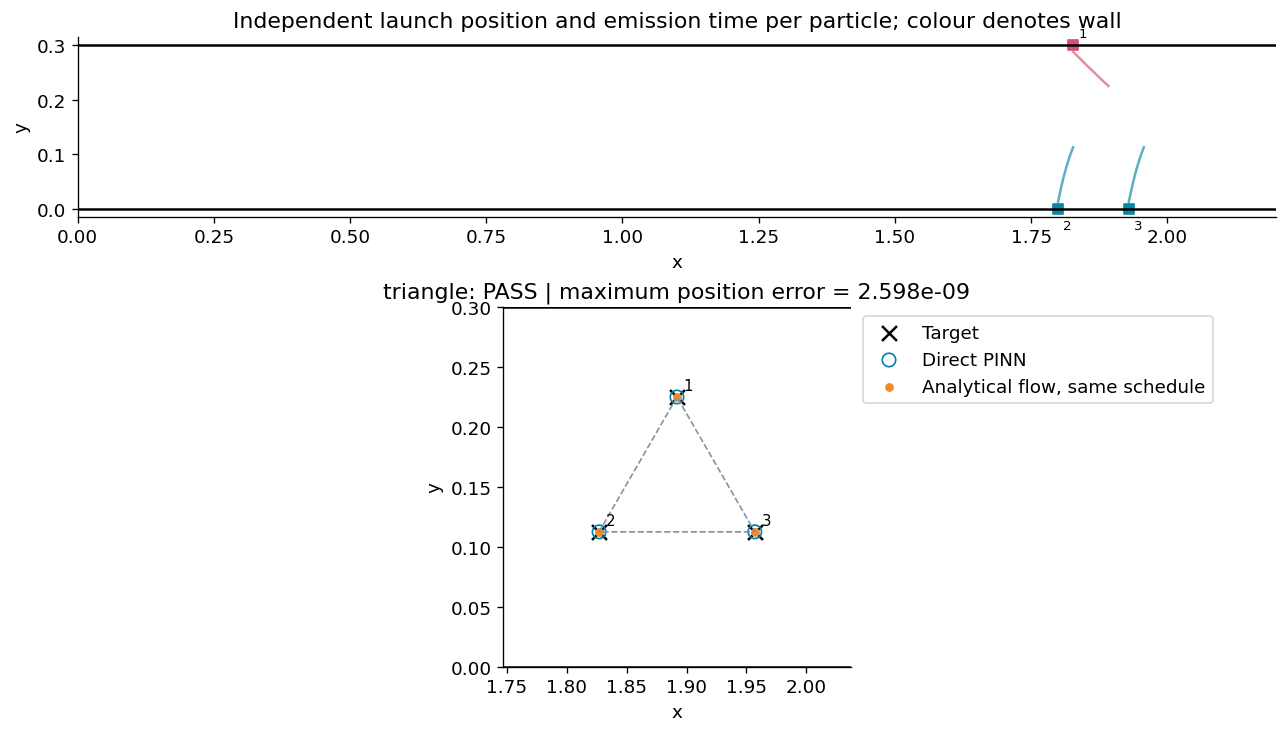

/kaggle/working/independent_particle_launch_1793532257819790971/formations/triangle/replay.html

/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


{"kind": "triangle", "success": true, "reason": "all numerical checks passed", "max_error": 2.597725263663327e-09, "min_pair_distance": 0.12990380971217813, "max_reference_error": 9.083507305792277e-07}

Optimizing: square
square candidate counts per particle: [16, 16, 16, 16]
square start 1: max error=2.264e-10; min separation=0.10607; 16 independent continuous decisions
square start 2: max error=2.264e-10; min separation=0.10607; 16 independent continuous decisions
square start 3: max error=2.264e-10; min separation=0.10607; 16 independent continuous decisions


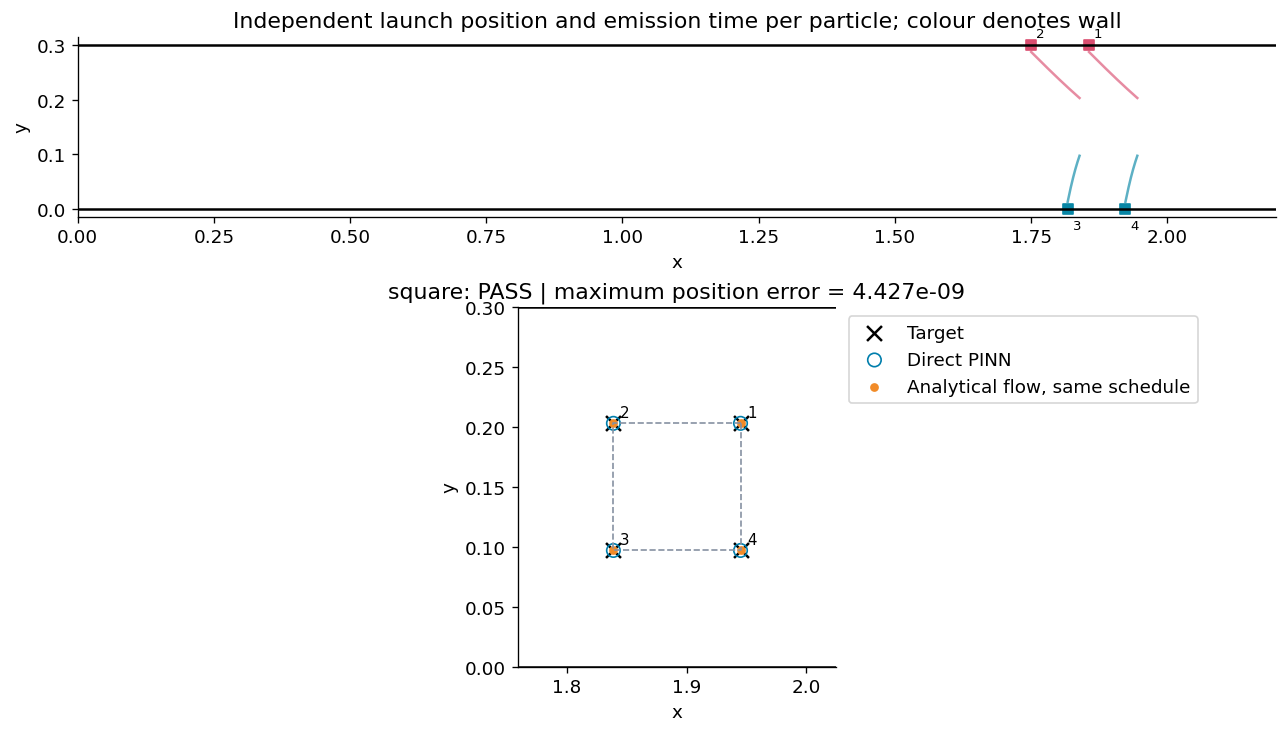

/kaggle/working/independent_particle_launch_1793532257819790971/formations/square/replay.html

{"kind": "square", "success": true, "reason": "all numerical checks passed", "max_error": 4.426638374594627e-09, "min_pair_distance": 0.10606590648706053, "max_reference_error": 7.550077632606226e-07}

Optimizing: circle_10
circle_10 candidate counts per particle: [16, 16, 16, 16, 16, 16, 16, 16, 16, 16]
circle_10 start 1: max error=6.95e-10; min separation=0.04595; 40 independent continuous decisions
circle_10 start 2: max error=6.95e-10; min separation=0.04595; 40 independent continuous decisions
circle_10 start 3: max error=6.95e-10; min separation=0.04595; 40 independent continuous decisions


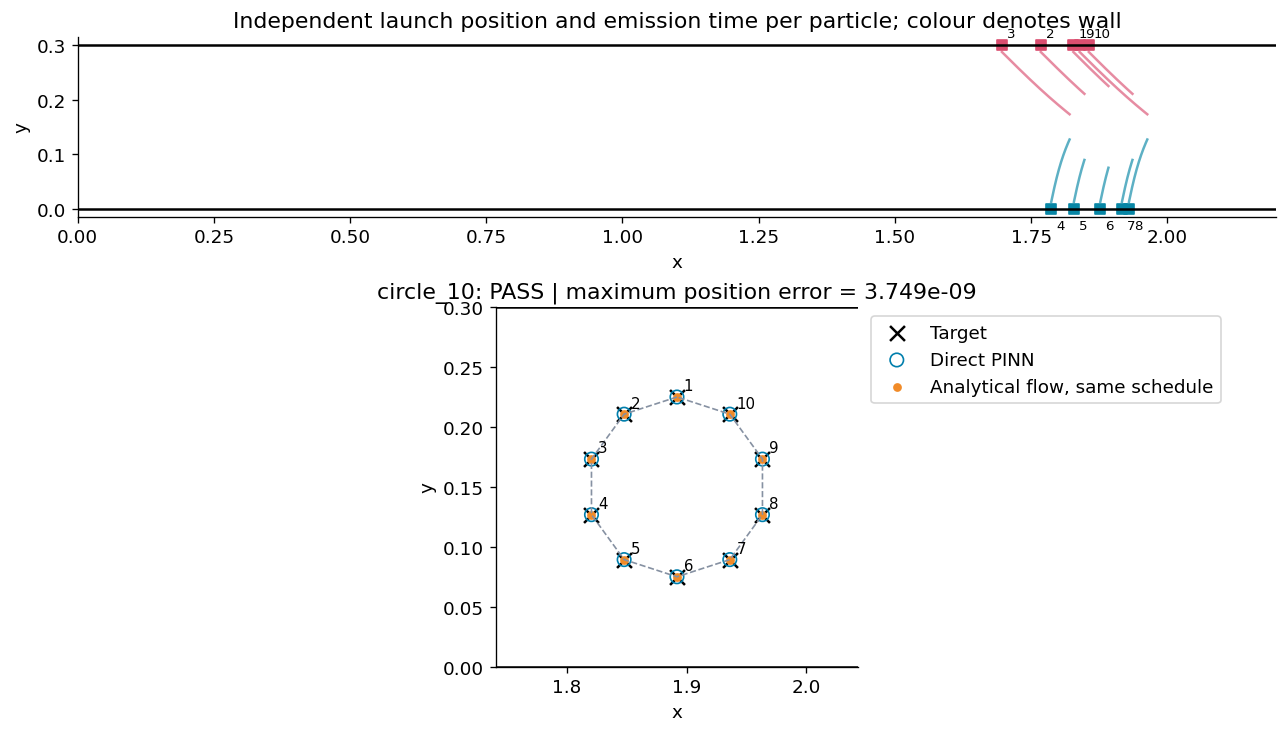

/kaggle/working/independent_particle_launch_1793532257819790971/formations/circle_10/replay.html

{"kind": "circle_10", "success": true, "reason": "all numerical checks passed", "max_error": 3.748608071484486e-09, "min_pair_distance": 0.04595032166324762, "max_reference_error": 1.7986695405943006e-06}

Optimizing: s_8
s_8 candidate counts per particle: [16, 16, 16, 16, 16, 16, 16, 16]
s_8 start 1: max error=1.921e-10; min separation=0.039173; 32 independent continuous decisions
s_8 start 2: max error=1.921e-10; min separation=0.039173; 32 independent continuous decisions
s_8 start 3: max error=1.921e-10; min separation=0.039173; 32 independent continuous decisions


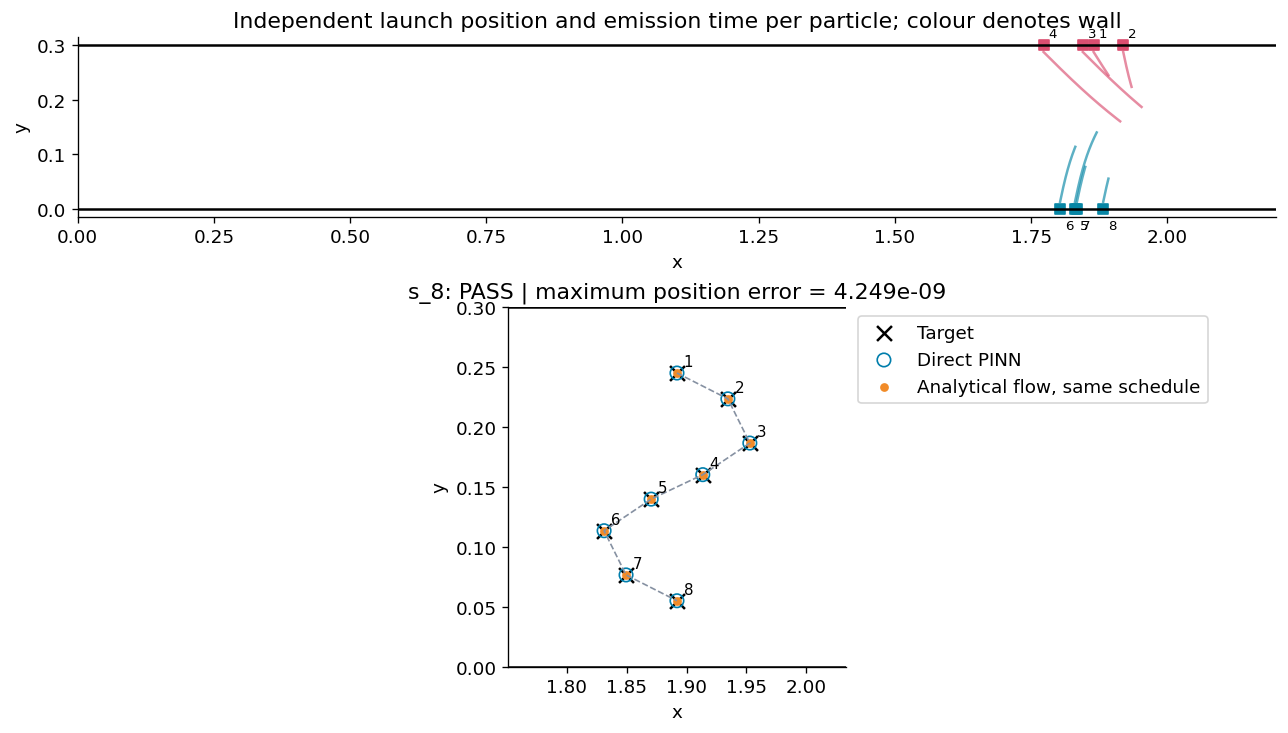

/kaggle/working/independent_particle_launch_1793532257819790971/formations/s_8/replay.html

{"kind": "s_8", "success": true, "reason": "all numerical checks passed", "max_error": 4.249070867761213e-09, "min_pair_distance": 0.0391726249672529, "max_reference_error": 2.005782371936913e-06}

Optimizing: chevron_7
chevron_7 candidate counts per particle: [16, 16, 16, 16, 16, 16, 16]
chevron_7 start 1: max error=2.721e-10; min separation=0.05; 28 independent continuous decisions
chevron_7 start 2: max error=2.721e-10; min separation=0.05; 28 independent continuous decisions
chevron_7 start 3: max error=2.721e-10; min separation=0.05; 28 independent continuous decisions


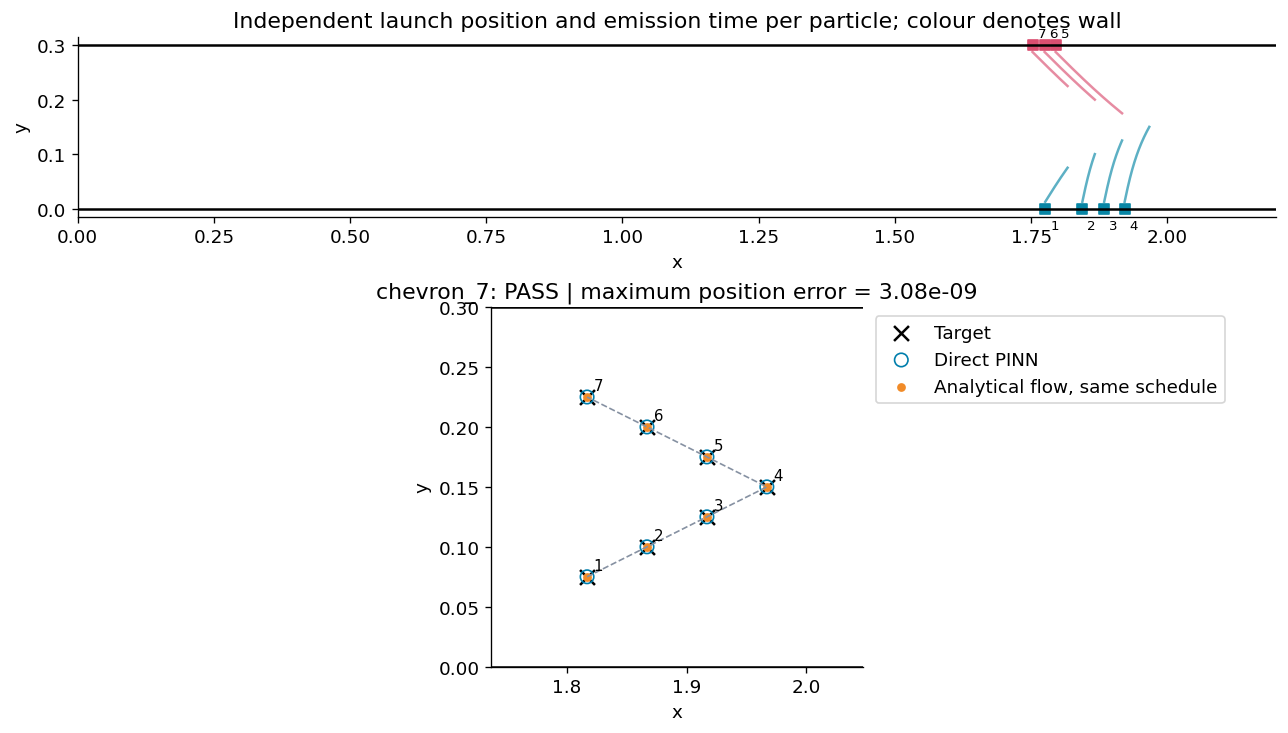

/kaggle/working/independent_particle_launch_1793532257819790971/formations/chevron_7/replay.html

{"kind": "chevron_7", "success": true, "reason": "all numerical checks passed", "max_error": 3.0804914672394523e-09, "min_pair_distance": 0.04999999888040234, "max_reference_error": 1.6277378954255604e-06}


/kaggle/working/independent_particle_launch_1793532257819790971/formation_laboratory.html

Independent launch results:


/kaggle/working/independent_particle_launch_1793532257819790971.zip

In [19]:
# اصلاح بهینه‌سازی پس از آموزش مدل نسخهٔ قبلی
# Paste this complete file into ONE new final cell of the original trained notebook.
# Or execute: exec(Path('/kaggle/working/Independent_Particle_Launch_Repair.py').read_text(), globals())
# No weights are trained or modified by this repair. Missing old definitions raise an error.
from pathlib import Path
import json, time, csv, shutil, itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize_scalar, brentq
from IPython.display import display, HTML, FileLink

_required = ['model', 'validate_model', 'FlowLookup', 'trace_particle', 'direct_field',
             'exact_flow', 'CONTROL_BOUNDS', 'CONTROL_MID', 'CONTROL_SPAN', 'RUN',
             'L', 'H', 'U_C', 'RE', 'DIAMETER', 'DENSITY_RATIO', 'LAUNCH_GAP',
             'TRAJECTORY_MAX_STEP', 'TRAJECTORY_TMAX', 'ODE_RTOL', 'ODE_ATOL', 'SEED',
             'ALLOW_UNVALIDATED_OPTIMIZATION']
_missing = [name for name in _required if name not in globals()]
if _missing:
    raise RuntimeError('Run the original rectangular notebook through section 6 first. '
                       'Missing definitions: '+', '.join(_missing))
_parent_run = Path(RUN)
RUN = _parent_run.parent / ('independent_particle_launch_'+str(time.time_ns()))
RUN.mkdir(parents=True)
for _name in ['best_model.pt', 'config.json', 'training_history.json', 'training_complete.json']:
    if (_parent_run/_name).is_file(): shutil.copy2(_parent_run/_name, RUN/_name)
(RUN/'repair_origin.json').write_text(json.dumps(dict(parent_run=str(_parent_run),
    change='independent launch position, velocity and emission time for every particle',
    training_performed=False), indent=2))
VALIDATION = validate_model(model)
print('Reusing trained model; fresh flow validation:', VALIDATION['passed'], flush=True)

# Each row of the design vector is [x_launch, u_launch, v_launch, age_at_target].
# The wall side is selected separately from candidate trajectories for EACH particle.
SHAPES = ['triangle', 'square', 'circle_10', 's_8', 'chevron_7']
TARGET_CENTER = np.array([0.86*L, H/2])
TARGET_RADIUS = 0.075
S_WIDTH, S_HEIGHT = 0.13, 0.19
POSITION_TOLERANCE = 0.003
COLLISION_MARGIN = 0.001
LEAD_TIME = 0.25
AGE_MAX = min(5.0, TRAJECTORY_TMAX)
SEED_U_SPEEDS = (.25, .70, 1.20)
SEED_V_SPEEDS = np.linspace(.15, 1.20, 15)
CANDIDATES_PER_SIDE = 8
OPT_STARTS = 3
COARSE_MAX_NFEV, DIRECT_MAX_NFEV = 50, 35
COLLISION_SAMPLES = 61
PAIR_VERIFY_SAMPLES = 601
CLEARANCE_RESERVE = 0.0003  # optimize with slack; retain the original PASS threshold.
REFERENCE_TOLERANCE = 0.004
RUN_OPTIMIZATION = True

assert AGE_MAX > .02 and min(OPT_STARTS, COARSE_MAX_NFEV, DIRECT_MAX_NFEV) >= 1
assert COLLISION_SAMPLES >= 3 and PAIR_VERIFY_SAMPLES >= 21
assert min(POSITION_TOLERANCE, COLLISION_MARGIN, LEAD_TIME, REFERENCE_TOLERANCE) > 0
OPT_CONFIG = dict(shapes=SHAPES, center=TARGET_CENTER.tolist(), radius=TARGET_RADIUS,
    s_width=S_WIDTH, s_height=S_HEIGHT, position_tolerance=POSITION_TOLERANCE,
    collision_margin=COLLISION_MARGIN, clearance_reserve=CLEARANCE_RESERVE,
    lead_time=LEAD_TIME, age_max=AGE_MAX, starts=OPT_STARTS,
    seed_u_speeds=list(SEED_U_SPEEDS), seed_v_speeds=SEED_V_SPEEDS.tolist(),
    candidates_per_side=CANDIDATES_PER_SIDE, coarse_max_nfev=COARSE_MAX_NFEV,
    direct_max_nfev=DIRECT_MAX_NFEV, collision_samples=COLLISION_SAMPLES,
    reference_tolerance=REFERENCE_TOLERANCE,
    control_mode='independent x_launch, u_launch, v_launch and age for EVERY particle',
    side_mode='each particle selects a wall from its candidate bank; held fixed in each local solve',
    emission_time='T=max(age)+lead_time; release_i=T-age_i',
    flow_conditioning='active wall triplet from particle i; inactive triplet at CONTROL_MID',
    hardware='spatially programmable virtual wall ports, not two stationary nozzles')
(RUN/'optimization_config.json').write_text(json.dumps(OPT_CONFIG, indent=2))

from collections import OrderedDict
from scipy.optimize import brentq


def target_points(kind):
    if kind in ['triangle', 'square'] or kind.startswith('circle_'):
        n = 3 if kind == 'triangle' else 4 if kind == 'square' else int(kind.split('_')[1])
        if not 3 <= n <= 40: raise ValueError('Polygon count must be 3..40.')
        phase = np.pi/4 if kind == 'square' else np.pi/2
        a = phase+np.arange(n)*2*np.pi/n
        pts = TARGET_CENTER+TARGET_RADIUS*np.column_stack((np.cos(a), np.sin(a)))
        closed = True
    elif kind.startswith('s_'):
        n = int(kind.split('_')[1]); t = np.linspace(0, 1, 2001)
        curve = np.column_stack((S_WIDTH/2*np.sin(2*np.pi*t), S_HEIGHT*(.5-t)))
        # Equal arclength spacing avoids visually uneven point density.
        arc = np.r_[0, np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))]
        knots = np.linspace(0, arc[-1], n)
        pts = TARGET_CENTER+np.column_stack([np.interp(knots, arc, curve[:, j]) for j in (0, 1)])
        closed = False
    elif kind.startswith('chevron_'):
        n = int(kind.split('_')[1]); t = np.linspace(-1, 1, n)
        pts = TARGET_CENTER+np.column_stack((TARGET_RADIUS*(1-2*np.abs(t)), TARGET_RADIUS*t))
        closed = False
    else: raise ValueError('Use triangle, square, circle_N, s_N or chevron_N.')
    if not 3 <= len(pts) <= 40: raise ValueError('Use 3..40 particles.')
    radius = DIAMETER/2
    if np.any(pts <= [radius, radius]) or np.any(pts >= [L-radius, H-radius]):
        raise ValueError(f'{kind}: target does not fit inside the rectangle with radius clearance.')
    distances = np.linalg.norm(pts[:, None]-pts[None, :], axis=2)
    np.fill_diagonal(distances, np.inf)
    if distances.min() < DIAMETER+COLLISION_MARGIN:
        raise ValueError(f'{kind}: target points overlap at the configured diameter.')
    return pts, closed


class IndependentLauncherPlanner:
    """One launch triplet and one physical flight age per particle, never shared.

    The six conditioning slots of the existing flow PINN remain unchanged.
    For each trajectory the active wall's three slots carry THAT particle's
    launch settings and the unused wall's three slots remain at their midpoints.
    This is valid for the declared one-way, control-independent carrier flow.
    """
    def __init__(self, field, label, rtol=2e-6, atol=2e-8, max_step=.06):
        self.field, self.label = field, label
        self.rtol, self.atol, self.max_step = rtol, atol, max_step
        self.cache, self.calls = OrderedDict(), 0

    def pack(self, controls, side, age):
        j = 3*int(side)
        return np.r_[(np.asarray(controls)[j:j+3]-CONTROL_BOUNDS[j:j+3, 0]) /
                     CONTROL_SPAN[j:j+3], age/AGE_MAX]

    def physical(self, row, side):
        row = np.clip(np.asarray(row, float), 0, 1)
        j = 3*int(side)
        controls = CONTROL_MID.copy()
        controls[j:j+3] = CONTROL_BOUNDS[j:j+3, 0]+row[:3]*CONTROL_SPAN[j:j+3]
        return controls, float(row[3]*AGE_MAX)

    def one_path(self, row, side):
        key = (int(side), *np.round(np.asarray(row), 12))
        if key in self.cache:
            self.cache.move_to_end(key)
            return self.cache[key]
        controls, age = self.physical(row, side)
        path = trace_particle(self.field, controls, int(side), tmax=max(age, 1e-8),
            rtol=self.rtol, atol=self.atol, max_step=self.max_step)
        if not path.ok: raise RuntimeError('Particle trajectory integration failed.')
        self.cache[key] = path
        self.calls += 1
        if len(self.cache) > 1024: self.cache.popitem(last=False)
        return path

    def endpoints(self, z, assignment):
        rows = np.asarray(z).reshape(len(assignment), 4)
        paths = [self.one_path(row, side) for row, side in zip(rows, assignment)]
        ages = rows[:, 3]*AGE_MAX
        actual = np.array([p.state([min(a, p.end)])[0, :2] for p, a in zip(paths, ages)])
        return paths, ages, actual

    def residual(self, z, assignment, targets):
        paths, ages, actual = self.endpoints(z, assignment)
        residual = list(((actual-targets)/H).ravel())
        # A terminated path cannot be silently held at its terminal position.
        residual.extend(3*max(0., a-p.end)/AGE_MAX for p, a in zip(paths, ages))
        required = DIAMETER+COLLISION_MARGIN+CLEARANCE_RESERVE
        for i in range(len(paths)):
            for j in range(i):
                backwards = np.linspace(0, min(ages[i], ages[j]), COLLISION_SAMPLES)
                # Clipping here keeps invalid iterates finite; the lifespan
                # residual penalizes them and strict final checks reject them.
                pi = paths[i].state(ages[i]-backwards, strict=False)[:, :2]
                pj = paths[j].state(ages[j]-backwards, strict=False)[:, :2]
                distance = np.linalg.norm(pi-pj, axis=1)
                residual.extend(4*np.maximum(0, required-distance)/H)
        return np.asarray(residual)

    def refine(self, z, assignment, targets, max_nfev):
        z = np.clip(np.asarray(z, float).ravel(), 0, 1)
        history = []
        def objective(point):
            residual = self.residual(point, assignment, targets)
            _, _, actual = self.endpoints(point, assignment)
            history.append(dict(evaluation=len(history), cost=float(np.dot(residual, residual)/2),
                max_error=float(np.linalg.norm(actual-targets, axis=1).max()),
                actual=actual.tolist()))
            return residual
        def jacobian(point):
            base = self.residual(point, assignment, targets)
            jac = np.empty((len(base), len(point)))
            for k in range(len(point)):
                # Absolute steps remain useful near zero; each perturbation
                # only re-integrates its own particle because of row caching.
                delta = 2e-4 if point[k]+2e-4 <= 1 else -2e-4
                trial = point.copy(); trial[k] += delta
                jac[:, k] = (self.residual(trial, assignment, targets)-base)/delta
            return jac
        result = least_squares(objective, z, jac=jacobian,
            bounds=(np.zeros(len(z)), np.ones(len(z))), max_nfev=max_nfev,
            ftol=5e-9, xtol=5e-8, gtol=5e-8)
        return result.x, dict(message=result.message, nfev=int(result.nfev),
            cost=float(result.cost), optimizer_terminated=bool(result.success), history=history,
            continuous_decisions=int(len(z)), per_particle_decisions=4)


def independent_seed_bank(planner):
    """Reusable seed trajectories; a shape can draw each particle from ANY row.

    Because the physical developed flow is independent of x, a seed trajectory
    can first be translated in x. It is then integrated again at its actual
    position with the lookup, and later with all eight direct PINN inputs.
    Translation is an initializer only; it is never the accepted trajectory.
    """
    bank = []
    for side, ux, speed in itertools.product((0, 1), SEED_U_SPEEDS, SEED_V_SPEEDS):
        j = 3*side
        c = CONTROL_MID.copy()
        c[j:j+3] = [min(.01, L/100), ux, speed if side == 0 else -speed]
        if np.any(c < CONTROL_BOUNDS[:, 0]) or np.any(c > CONTROL_BOUNDS[:, 1]):
            continue
        path = trace_particle(planner.field, c, side, tmax=AGE_MAX,
            rtol=planner.rtol, atol=planner.atol, max_step=planner.max_step)
        if path.ok and path.end > .02:
            ages = np.linspace(0, path.end, 401)
            bank.append(dict(controls=c, side=side, path=path,
                             ages=ages, points=path.state(ages)[:, :2]))
    if not bank: raise RuntimeError('No usable independent launch seeds.')
    print(f'Independent seed bank: {len(bank)} reusable paths; controls can differ for every particle.', flush=True)
    return bank


def options_for_particle(planner, bank, target):
    options = []
    for seed in bank:
        path, side, c = seed['path'], seed['side'], seed['controls'].copy()
        ydiff = seed['points'][:, 1]-target[1]
        crossings = np.flatnonzero(ydiff[:-1]*ydiff[1:] <= 0)
        if not len(crossings): continue
        k = int(crossings[0])
        age = brentq(lambda a: float(path.state([a])[0, 1]-target[1]),
                     seed['ages'][k], seed['ages'][k+1], xtol=1e-11)
        if age < .02: continue
        state = path.state([age])[0]
        j = 3*side
        c[j] += target[0]-state[0]
        if not 0 <= c[j] <= L: continue
        row = planner.pack(c, side, age)
        translated = planner.one_path(row, side)
        if translated.end < age-1e-8: continue
        actual = translated.state([age])[0, :2]
        options.append(dict(row=row, side=side, path=translated, age=age,
                            error=float(np.linalg.norm(actual-target))))
    if not options:
        raise RuntimeError(f'No seed reaches target {target.tolist()} within current bounds. '
                           'Expand the seed grid or flight-age budget; this is not an impossibility proof.')
    # Retain diverse launch locations, speeds and ages on each available wall.
    chosen = []
    for side in (0, 1):
        group = sorted([o for o in options if o['side'] == side], key=lambda o: o['error'])
        if not group: continue
        selected = [group.pop(0)]
        while group and len(selected) < CANDIDATES_PER_SIDE:
            k = max(range(len(group)), key=lambda k:
                min(np.linalg.norm(group[k]['row']-s['row']) for s in selected) -
                20*group[k]['error']/H)
            selected.append(group.pop(k))
        chosen.extend(selected)
    return chosen


def choose_independent_seeds(options, start):
    """Discrete search for a compatible set of individual launch candidates."""
    generator = np.random.default_rng(SEED+301+start)
    ids = [int(generator.integers(len(o))) for o in options]
    if start == 0:
        ids = [min(range(len(o)), key=lambda k: o[k]['error']) for o in options]
    cache = {}
    required = DIAMETER+COLLISION_MARGIN+CLEARANCE_RESERVE
    def pair_cost(i, ki, j, kj):
        if j > i: i, ki, j, kj = j, kj, i, ki
        key = (i, ki, j, kj)
        if key not in cache:
            a, b = options[i][ki], options[j][kj]
            backwards = np.linspace(0, min(a['age'], b['age']), COLLISION_SAMPLES)
            p = a['path'].state(a['age']-backwards)[:, :2]
            q = b['path'].state(b['age']-backwards)[:, :2]
            deficit = max(0., required-float(np.linalg.norm(p-q, axis=1).min()))/H
            cache[key] = 20*deficit**2
        return cache[key]
    for sweep in range(8):
        changed = False
        for i in generator.permutation(len(options)):
            costs = [(o['error']/H)**2 + sum(pair_cost(i, k, j, ids[j])
                      for j in range(len(options)) if i != j)
                     for k, o in enumerate(options[i])]
            k = int(np.argmin(costs))
            if costs[k]+1e-14 < costs[ids[i]]:
                ids[i], changed = k, True
        if not changed: break
    chosen = [options[i][k] for i, k in enumerate(ids)]
    return np.array([o['row'] for o in chosen]).ravel(), np.array([o['side'] for o in chosen], int)


def minimum_separation(paths, ages, samples=PAIR_VERIFY_SAMPLES, refine=True):
    """Distance only while both particles exist, using the SAME global clock."""
    minimum = float('inf')
    for i in range(len(paths)):
        for j in range(i):
            end = min(ages[i], ages[j])
            def distance(backwards):
                backwards = np.atleast_1d(backwards)
                a = paths[i].state(ages[i]-backwards)[:, :2]
                b = paths[j].state(ages[j]-backwards)[:, :2]
                return np.linalg.norm(a-b, axis=1)
            times = np.linspace(0, end, samples)
            d = distance(times); minimum = min(minimum, float(d.min()))
            if refine and end > 0:
                local = np.flatnonzero((d[1:-1] <= d[:-2]) & (d[1:-1] <= d[2:]))+1
                for k in local:
                    result = minimize_scalar(lambda t: float(distance(t)[0]),
                        bounds=(times[k-1], times[k+1]), method='bounded', options={'xatol': 1e-10})
                    minimum = min(minimum, float(result.fun))
    return minimum


def independent_candidate(planner, z, assignment, targets, diagnostics):
    paths, ages, actual = planner.endpoints(z, assignment)
    valid = all(p.ok and a <= p.end+1e-8 for p, a in zip(paths, ages))
    errors = np.linalg.norm(actual-targets, axis=1)
    sep = minimum_separation(paths, ages) if valid else 0.
    score = (max(0, float(errors.max())-POSITION_TOLERANCE)/H +
             2*max(0, DIAMETER+COLLISION_MARGIN+CLEARANCE_RESERVE-sep)/H + (0 if valid else 10))
    return dict(z=np.asarray(z).copy(), assignment=np.asarray(assignment).copy(), paths=paths,
        ages=ages, actual=actual, errors=errors, separation=sep, score=score, diagnostics=diagnostics)


def plan_formation(kind, coarse, direct, bank):
    targets, closed = target_points(kind)
    candidates, logs = [], []
    options = [options_for_particle(coarse, bank, point) for point in targets]
    print(kind, 'candidate counts per particle:', [len(o) for o in options], flush=True)
    for start in range(OPT_STARTS):
        try:
            initial, assignment = choose_independent_seeds(options, start)
            candidates.append(independent_candidate(coarse, initial, assignment, targets,
                                                      dict(stage='independent_seed_selection')))
            z, diag = coarse.refine(initial, assignment, targets, COARSE_MAX_NFEV)
            candidate = independent_candidate(coarse, z, assignment, targets, diag)
            candidates.append(candidate)
            print(f'{kind} start {start+1}: max error={candidate["errors"].max():.4g}; '
                  f'min separation={candidate["separation"]:.5g}; '
                  f'{4*len(targets)} independent continuous decisions', flush=True)
        except (RuntimeError, FloatingPointError, ValueError) as exc:
            logs.append(dict(stage='lookup', start=start+1, error=str(exc)))
    if not candidates:
        return dict(kind=kind, success=False, reason='All independent searches failed.', failures=logs)
    candidates.sort(key=lambda c: (c['score'], float(c['errors'].max())))
    verified = []
    for candidate in candidates[:min(2, len(candidates))]:
        try:
            verified.append(independent_candidate(direct, candidate['z'], candidate['assignment'], targets,
                                                  dict(stage='direct_before_refinement')))
            z, diag = direct.refine(candidate['z'], candidate['assignment'], targets, DIRECT_MAX_NFEV)
            diag['coarse_history'] = candidate['diagnostics'].get('history', [])
            verified.append(independent_candidate(direct, z, candidate['assignment'], targets, diag))
        except (RuntimeError, FloatingPointError, ValueError) as exc:
            logs.append(dict(stage='direct', error=str(exc)))
    if not verified:
        return dict(kind=kind, success=False, reason='Direct PINN search failed.', failures=logs)
    verified.sort(key=lambda c: (c['score'], float(c['errors'].max())))
    best = verified[0]
    assignment, ages = best['assignment'], best['ages']
    controls = [direct.physical(row, side)[0]
                for row, side in zip(best['z'].reshape(-1, 4), assignment)]
    strict_paths, reference_paths = [], []
    for c, side, age in zip(controls, assignment, ages):
        strict_paths.append(trace_particle(direct.field, c, int(side), tmax=age,
            rtol=2e-9, atol=2e-11, max_step=TRAJECTORY_MAX_STEP/2))
        reference_paths.append(trace_particle(exact_flow, c, int(side), tmax=age,
            rtol=2e-10, atol=2e-12, max_step=TRAJECTORY_MAX_STEP/2))
    strict_valid = all(p.ok and a <= p.end+1e-8 for p, a in zip(strict_paths, ages))
    reference_valid = all(p.ok and a <= p.end+1e-8 for p, a in zip(reference_paths, ages))
    actual = np.array([p.state([a], strict=False)[0, :2] for p, a in zip(strict_paths, ages)])
    reference = np.array([p.state([a], strict=False)[0, :2] for p, a in zip(reference_paths, ages)])
    errors = np.linalg.norm(actual-targets, axis=1)
    ref_errors = np.linalg.norm(reference-targets, axis=1)
    delta = np.linalg.norm(reference-actual, axis=1)
    sep = minimum_separation(strict_paths, ages) if strict_valid else 0.
    ref_sep = minimum_separation(reference_paths, ages) if reference_valid else 0.
    T = float(ages.max()+LEAD_TIME)
    release = T-ages
    position_ok = bool(strict_valid and errors.max() <= POSITION_TOLERANCE)
    clearance_ok = bool(strict_valid and sep >= DIAMETER+COLLISION_MARGIN)
    reference_ok = bool(reference_valid and ref_errors.max() <= REFERENCE_TOLERANCE and
                        delta.max() <= REFERENCE_TOLERANCE and ref_sep >= DIAMETER+COLLISION_MARGIN)
    quality_ok = bool(VALIDATION['passed'])
    success = bool(position_ok and clearance_ok and reference_ok and quality_ok)
    schedule, trajectories = [], []
    for i, (c, side, path) in enumerate(zip(controls, assignment, strict_paths)):
        j = 3*side
        schedule.append(dict(particle=i+1, launcher=['bottom', 'top'][side],
            x_launch=float(c[j]), y_launch=float(path.state([0])[0, 1]),
            u_launch=float(c[j+1]), v_launch=float(c[j+2]),
            release_time=float(release[i]), age_at_target=float(ages[i]),
            target_x=float(targets[i, 0]), target_y=float(targets[i, 1]),
            actual_x=float(actual[i, 0]), actual_y=float(actual[i, 1]),
            position_error=float(errors[i]), reference_error=float(ref_errors[i])))
        sample_ages = np.linspace(0, min(ages[i], path.end), 501)
        trajectories.append(dict(particle=i+1, side=int(side), release=float(release[i]),
            flow_controls=c.tolist(), ages=sample_ages.tolist(), states=path.state(sample_ages).tolist()))
    reasons = []
    if not position_ok: reasons.append('target tolerance missed or premature trajectory termination')
    if not clearance_ok: reasons.append('particle clearance failed')
    if not reference_ok: reasons.append('analytical-flow cross-check failed')
    if not quality_ok: reasons.append('flow model validation failed')
    return dict(kind=kind, closed=closed, success=success,
        reason='all numerical checks passed' if success else '; '.join(reasons),
        flow_validated=quality_ok, position_success=position_ok, clearance_success=clearance_ok,
        reference_success=reference_ok, target_time=T, control_mode='per-particle-independent',
        continuous_decisions=4*len(targets), targets=targets.tolist(), actual=actual.tolist(),
        analytical_reference=reference.tolist(), max_error=float(errors.max()),
        rms_error=float(np.sqrt(np.mean(errors**2))), max_reference_error=float(ref_errors.max()),
        max_PINN_reference_delta=float(delta.max()), min_pair_distance=float(sep),
        reference_min_pair_distance=float(ref_sep), required_pair_distance=DIAMETER+COLLISION_MARGIN,
        schedules=schedule, paths=trajectories, failures=logs, optimization=best['diagnostics'],
        interpretation='Finite independent per-particle multistart search; simultaneous snapshot only',
        collision_check='Shared-time sampling and local scalar refinement; no contact forces or continuous certificate')



def write_schedule(path, rows):
    if not rows: return
    with path.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)


def plot_formation(result, directory):
    if 'actual' not in result: return
    target, actual = np.array(result['targets']), np.array(result['actual'])
    reference = np.array(result['analytical_reference'])
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout='constrained',
                             gridspec_kw={'height_ratios': [1, 2]})
    ax = axes[0]
    for trajectory in result['paths']:
        xy = np.array(trajectory['states'])[:, :2]
        ax.plot(xy[:, 0], xy[:, 1], color=['#0786a5', '#da4e70'][trajectory['side']], alpha=.65)
    for row in result['schedules']:
        side = int(row['launcher'] == 'top')
        ax.scatter(row['x_launch'], H if side else 0, marker='s', s=40, color=['#0786a5', '#da4e70'][side])
        ax.annotate(str(row['particle']), (row['x_launch'], H if side else 0),
                    xytext=(3, 5 if side else -12), textcoords='offset points', fontsize=8)
    for a in axes: a.axhline(0, color='k'); a.axhline(H, color='k'); a.set(xlabel='x', ylabel='y', aspect='equal')
    ax.set(xlim=(0, L), ylim=(-.015, H+.015), title='Independent launch position and emission time per particle; colour denotes wall')
    ax = axes[1]
    order = np.r_[np.arange(len(target)), 0] if result['closed'] else np.arange(len(target))
    ax.plot(target[order, 0], target[order, 1], '--', color='#8691a2', linewidth=1)
    ax.scatter(target[:, 0], target[:, 1], marker='x', s=80, color='black', label='Target')
    ax.scatter(actual[:, 0], actual[:, 1], s=65, facecolors='none', edgecolors='#007eac', label='Direct PINN')
    ax.scatter(reference[:, 0], reference[:, 1], s=18, color='#f18b28', label='Analytical flow, same schedule')
    for i, (a, b) in enumerate(zip(target, actual)):
        ax.plot([a[0], b[0]], [a[1], b[1]], color='#d14f66', linewidth=1)
        ax.annotate(str(i+1), b, xytext=(4, 4), textcoords='offset points', fontsize=9)
    ax.set(xlim=(max(0, target[:, 0].min()-.08), min(L, target[:, 0].max()+.08)),
           ylim=(0, H), title=f'{result["kind"]}: {"PASS" if result["success"] else "BEST FOUND / CHECKS FAILED"}'
           f' | maximum position error = {result["max_error"]:.4g}')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    fig.savefig(directory/'formation.png', dpi=240)
    plt.show()


REPLAY_TEMPLATE = '<!doctype html><html lang="en"><meta charset="utf-8">\n<meta name="viewport" content="width=device-width,initial-scale=1">\n<title>Independent particle injection · formation laboratory</title>\n<style>\n:root{color-scheme:dark}*{box-sizing:border-box}body{font:15px system-ui;background:#0d1729;color:#dceaf5;margin:0;padding:24px}\nmain{max-width:1280px;margin:auto}h1{font-size:26px;margin:7px 0}p{color:#a8bdd0;line-height:1.6}header,.toolbar,.card{background:#15253a;border:1px solid #2c4259;border-radius:14px;padding:16px;margin-bottom:15px}\n.toolbar{display:flex;gap:12px;align-items:center;flex-wrap:wrap}button,select{background:#29475e;color:#eff9ff;border:0;border-radius:8px;padding:9px 15px}button.active{background:#72e5d0;color:#102339}\ninput[type=range]{flex:1;min-width:170px;accent-color:#72e5d0}label{display:flex;gap:7px;align-items:center}canvas{display:block;width:100%;background:#edf6fc;border-radius:10px}\n.panels{display:grid;grid-template-columns:1.6fr 1fr;gap:15px}.caption{font-size:12px;color:#a8bdd0;margin:8px 0}.status{padding:9px 12px;border-radius:7px;background:#253649;white-space:pre-wrap}\n.ok{color:#82ecd1}.fail{color:#ffb5b5}.stats{display:flex;gap:24px;flex-wrap:wrap;margin-top:10px}.stats b{font-size:19px;display:block;color:#edf8ff}.scroll{overflow:auto;max-height:320px}\ntable{border-collapse:collapse;width:100%;font-size:12px;font-variant-numeric:tabular-nums}td,th{padding:8px 10px;text-align:right;border-bottom:1px solid #30465b}th{color:#a8bdd0;position:sticky;top:0;background:#15253a}td:first-child,th:first-child{text-align:left}\n@media(max-width:850px){body{padding:10px}.panels{grid-template-columns:1fr}h1{font-size:21px}}\n</style><main>\n<header><div class="caption">RECTANGULAR POISEUILLE FLOW · INDEPENDENT WALL PORTS</div>\n<h1>Particle formation laboratory</h1><p>Every particle has its own wall, launch position, initial velocity and release time. The final shape is a simultaneous snapshot inside the channel.</p>\n<div class="toolbar"><label>Experiment <select id="shape"></select></label><button id="replay" class="active">Injection replay</button><button id="opt">Optimization progress</button><button id="csv">Download launch schedule</button></div>\n<div id="status" class="status"></div><div class="stats" id="stats"></div></header>\n<div class="toolbar"><button id="play">Play</button><button id="restart">Restart</button><input id="time" type="range" min="0" max="1" step="any" value="0"><output id="clock"></output>\n<label>Speed <select id="speed"><option value=".5">0.5×</option><option value="1" selected>1×</option><option value="2">2×</option><option value="4">4×</option></select></label>\n<label><input id="ghosts" type="checkbox" checked>Show paths</label></div>\n<div class="panels"><div class="card"><canvas id="full" width="1200" height="400"></canvas><p class="caption" id="caption">Launch squares are numbered by particle; colour denotes wall. Unreleased particles do not appear in the flow.</p></div>\n<div class="card"><canvas id="zoom" width="700" height="650"></canvas><p class="caption">Target region · dashed crosses: target; solid particles: actual positions. Particle radii use the physical diameter.</p></div></div>\n<div class="card"><h3>Independent launch schedule</h3><div class="scroll"><table><thead><tr><th>Particle / wall</th><th>x launch</th><th>u launch</th><th>v launch</th><th>Release t</th><th>Flight age</th><th>Position error</th></tr></thead><tbody id="rows"></tbody></table></div>\n<p class="caption">Offline replay of saved ODE trajectories. Numerical clearance checks do not include particle contact forces. The flow model and each final schedule must pass their own validation checks.</p></div>\n</main><script>\nconst D=__DATA__,$=s=>document.getElementById(s),COLORS=[\'#0786a5\',\'#da4e70\'];\nlet current,mode=\'replay\',clock=0,playing=false,last=null,history=[];\nfunction sample(path,age){let a=path.ages,z=path.states;if(age<-1e-9||age>a[a.length-1]+1e-8)return null;if(age<=a[0])return z[0].slice(0,2);if(age>=a[a.length-1])return z[z.length-1].slice(0,2);let l=0,h=a.length-1;while(h-l>1){let m=(h+l)>>1;if(a[m]<=age)l=m;else h=m;}let f=(age-a[l])/(a[h]-a[l]);return [z[l][0]*(1-f)+z[h][0]*f,z[l][1]*(1-f)+z[h][1]*f];}\nfunction transform(canvas,zoom){let targets=current.targets,xs=targets.map(p=>p[0]),ys=targets.map(p=>p[1]),xmin=zoom?Math.max(0,Math.min(...xs)-.06):0,xmax=zoom?Math.min(D.L,Math.max(...xs)+.06):D.L,ymin=zoom?Math.max(0,Math.min(...ys)-.04):-.025,ymax=zoom?Math.min(D.H,Math.max(...ys)+.04):D.H+.025;let scale=Math.min((canvas.width-70)/(xmax-xmin),(canvas.height-70)/(ymax-ymin));return {scale,map:p=>[canvas.width/2+(p[0]-(xmin+xmax)/2)*scale,canvas.height/2-(p[1]-(ymin+ymax)/2)*scale]};}\nfunction draw(canvas,zoom){let c=canvas.getContext(\'2d\'),{scale,map}=transform(canvas,zoom);c.clearRect(0,0,canvas.width,canvas.height);\nfunction line(points,close=false){c.beginPath();points.forEach((p,i)=>{let q=map(p);if(i)c.lineTo(...q);else c.moveTo(...q)});if(close)c.closePath();}\nc.strokeStyle=\'#324d6a\';c.lineWidth=2;for(let y of [0,D.H]){line([[0,y],[D.L,y]]);c.stroke();}\nc.strokeStyle=\'#7a8fa4\';c.lineWidth=1.6;c.setLineDash([5,5]);line(current.targets,current.closed);c.stroke();c.setLineDash([]);\nfor(let p of current.targets){let [x,y]=map(p);c.beginPath();c.moveTo(x-5,y-5);c.lineTo(x+5,y+5);c.moveTo(x-5,y+5);c.lineTo(x+5,y-5);c.stroke();}\nlet finalPoints=[];\nif(mode===\'opt\'){let step=history[Math.min(history.length-1,Math.floor(clock))];if(step){finalPoints=step.actual;for(let i=0;i<step.actual.length;i++){let p=step.actual[i],target=current.targets[i];c.strokeStyle=\'#ce606f\';line([p,target]);c.stroke();let q=map(p);c.fillStyle=COLORS[current.paths[i].side];c.beginPath();c.arc(...q,Math.max(3,D.diameter*scale/2),0,Math.PI*2);c.fill();c.fillStyle=\'#263e54\';c.font=\'16px system-ui\';c.fillText(String(i+1),q[0]+7,q[1]-7);}}}\nelse{for(let p of current.paths){let row=current.schedules[p.particle-1],age=clock-p.release,col=COLORS[p.side];c.strokeStyle=col;\nif($(\'ghosts\').checked){c.globalAlpha=.18;line(p.states.map(z=>z.slice(0,2)));c.stroke();c.globalAlpha=1;}\nif(!zoom){let q=map([row.x_launch,p.side?D.H:0]);c.fillStyle=age>=-1e-9?col:\'#afbdc9\';c.fillRect(q[0]-5,q[1]-5,10,10);c.fillStyle=col;c.font=\'15px system-ui\';c.fillText(String(p.particle),q[0]+7,q[1]+(p.side?-9:19));}\nlet point=sample(p,age);if(!point)continue;finalPoints.push(point);let q=map(point);c.fillStyle=col;c.beginPath();c.arc(...q,Math.max(3,D.diameter*scale/2),0,2*Math.PI);c.fill();c.fillStyle=\'#263e54\';c.font=\'16px system-ui\';c.fillText(String(p.particle),q[0]+7,q[1]-7);}}\nif(finalPoints.length===current.paths.length&&(mode===\'opt\'||clock>=current.target_time-1e-7)){c.strokeStyle=\'#163c59\';c.lineWidth=1.4;line(finalPoints,current.closed);c.stroke();}\n}\nfunction maxClock(){return mode===\'opt\'?Math.max(0,history.length-1):current.target_time;}\nfunction refresh(){if(!current)return;draw($(\'full\'),false);draw($(\'zoom\'),true);$(\'time\').value=clock;$(\'clock\').textContent=mode===\'opt\'?`Evaluation ${Math.floor(clock)+1} / ${history.length}`:`t = ${clock.toFixed(3)} / ${current.target_time.toFixed(3)}`;$(\'play\').textContent=playing?\'Pause\':\'Play\';}\nfunction choose(){current=D.results[$(\'shape\').selectedIndex];clock=0;playing=false;last=null;let opt=current.optimization||{};history=[...(opt.coarse_history||[]),...(opt.history||[])];if(!history.length)history=[{actual:current.actual,max_error:current.max_error}];\n$(\'status\').className=\'status \'+(current.success?\'ok\':\'fail\');$(\'status\').textContent=`${current.kind} · ${current.success?\'PASS\':\'BEST FOUND / CHECKS FAILED\'} · ${current.reason}`+(current.verification_mode?`\\n${current.verification_mode}`:\'\');\nlet metrics=[[\'Position error\',current.max_error.toExponential(2)],[\'Minimum separation\',current.min_pair_distance.toFixed(5)],[\'Required separation\',current.required_pair_distance.toFixed(5)],[\'Continuous decisions\',String(current.continuous_decisions)]];$(\'stats\').replaceChildren();for(let [name,value] of metrics){let e=document.createElement(\'div\'),b=document.createElement(\'b\');e.textContent=name;b.textContent=value;e.appendChild(b);$(\'stats\').appendChild(e);}\n$(\'rows\').replaceChildren();for(let r of current.schedules){let tr=document.createElement(\'tr\');for(let value of [`${r.particle} / ${r.launcher}`,...[\'x_launch\',\'u_launch\',\'v_launch\',\'release_time\',\'age_at_target\',\'position_error\'].map(k=>r[k].toFixed(6))]){let td=document.createElement(\'td\');td.textContent=value;tr.appendChild(td);}$(\'rows\').appendChild(tr);}\n$(\'time\').max=maxClock();refresh();}\nfunction switchMode(next){mode=next;$(\'replay\').classList.toggle(\'active\',mode===\'replay\');$(\'opt\').classList.toggle(\'active\',mode===\'opt\');clock=0;playing=false;last=null;$(\'time\').max=maxClock();refresh();}\n$(\'replay\').onclick=()=>switchMode(\'replay\');$(\'opt\').onclick=()=>switchMode(\'opt\');$(\'shape\').onchange=choose;$(\'time\').oninput=e=>{clock=+e.target.value;playing=false;refresh();};$(\'ghosts\').onchange=refresh;\n$(\'play\').onclick=()=>{if(clock>=maxClock())clock=0;playing=!playing;last=null;refresh();};$(\'restart\').onclick=()=>{clock=0;playing=true;last=null;refresh();};\n$(\'csv\').onclick=()=>{let rows=current.schedules,keys=Object.keys(rows[0]),content=keys.join(\',\')+\'\\n\'+rows.map(r=>keys.map(k=>r[k]).join(\',\')).join(\'\\n\'),url=URL.createObjectURL(new Blob([content],{type:\'text/csv\'})),a=document.createElement(\'a\');a.href=url;a.download=current.kind+\'_independent_launch_schedule.csv\';a.click();setTimeout(()=>URL.revokeObjectURL(url),1000);};\nfor(let result of D.results){let option=document.createElement(\'option\');option.textContent=result.kind;$(\'shape\').appendChild(option);}choose();\nfunction tick(now){if(playing&&last!==null){clock=Math.min(maxClock(),clock+Math.min((now-last)/1000,.1)*Number($(\'speed\').value)*maxClock()/12);if(clock>=maxClock())playing=false;refresh();}last=now;requestAnimationFrame(tick);}requestAnimationFrame(tick);\n</script></html>\n'

def write_formation_animation(result, path):
    data = dict(results=[result], L=L, H=H, diameter=DIAMETER)
    path.write_text(REPLAY_TEMPLATE.replace('__DATA__', json.dumps(data, allow_nan=False)), encoding='utf-8')


def write_formation_dashboard(results, path):
    valid = [r for r in results if r.get('paths') and r.get('schedules')]
    if not valid: return None
    data = dict(results=valid, L=L, H=H, diameter=DIAMETER)
    path.write_text(REPLAY_TEMPLATE.replace('__DATA__', json.dumps(data, allow_nan=False)), encoding='utf-8')
    return path


FORMATION_RESULTS = []
if RUN_OPTIMIZATION:
    if not VALIDATION['passed'] and not ALLOW_UNVALIDATED_OPTIMIZATION:
        raise RuntimeError('Flow validation failed. Inspect validation.json, increase training '
            'and rerun validation before optimizing. Exploratory override is in settings; '
            'overridden runs can never be labelled successful.')
    # Freeze all neural weights. Optimization changes controls and release ages only.
    model.eval().requires_grad_(False)
    lookup = FlowLookup(model)
    test_xy = np.random.default_rng(SEED+421).uniform([0, 0], [L, H], (2000, 2))
    lookup_error = float(np.max(np.abs(lookup(test_xy)-direct_field(test_xy, CONTROL_MID))))
    (RUN/'lookup_validation.json').write_text(json.dumps(dict(
        max_velocity_interpolation_error=lookup_error, controls=CONTROL_MID.tolist(),
        note='Search acceleration only. All final trajectories use the full 8-input PINN.'), indent=2))
    coarse = IndependentLauncherPlanner(lookup, 'lookup')
    direct = IndependentLauncherPlanner(direct_field, 'direct PINN', rtol=ODE_RTOL,
                                  atol=ODE_ATOL, max_step=TRAJECTORY_MAX_STEP)
    bank = independent_seed_bank(coarse)
    for kind in SHAPES:
        directory = RUN/'formations'/kind
        directory.mkdir(parents=True, exist_ok=True)
        print('\nOptimizing:', kind, flush=True)
        try:
            result = plan_formation(kind, coarse, direct, bank)
        except (RuntimeError, ValueError, FloatingPointError) as exc:
            result = dict(kind=kind, success=False, reason=str(exc))
        FORMATION_RESULTS.append(result)
        (directory/'result.json').write_text(json.dumps(result, indent=2))
        if 'schedules' in result:
            write_schedule(directory/'release_schedule.csv', result['schedules'])
            flat = []
            for trajectory in result['paths']:
                for age, state in zip(trajectory['ages'], trajectory['states']):
                    flat.append(dict(particle=trajectory['particle'], side=trajectory['side'],
                        time=age+trajectory['release'], age=age, x=state[0], y=state[1],
                        u=state[2], v=state[3]))
            write_schedule(directory/'trajectories.csv', flat)
            write_formation_animation(result, directory/'replay.html')
            plot_formation(result, directory)
            display(FileLink(str(directory/'replay.html')))
            # Interactive replay is visible inside Kaggle/Colab as well as downloadable.
            import html as _html
            replay_html = (directory/'replay.html').read_text()
            display(HTML('<iframe style="width:100%;height:1060px;border:0;border-radius:12px" srcdoc="' +
                         _html.escape(replay_html, quote=True) + '"></iframe>'))
        print(json.dumps({key: result[key] for key in
            ['kind', 'success', 'reason', 'max_error', 'min_pair_distance', 'max_reference_error']
            if key in result}), flush=True)
        # Persist after each experiment so a later interruption loses no earlier results.
        (RUN/'formation_summary.json').write_text(json.dumps([
            {key: val for key, val in r.items() if key not in ['paths', 'schedules']}
            for r in FORMATION_RESULTS], indent=2))
    summary_rows = [{key: r.get(key) for key in ['kind', 'success', 'max_error',
        'rms_error', 'min_pair_distance', 'max_reference_error', 'reason']} for r in FORMATION_RESULTS]
    write_schedule(RUN/'formation_summary.csv', summary_rows)
    DASHBOARD_PATH = write_formation_dashboard(FORMATION_RESULTS, RUN/'formation_laboratory.html')
    if DASHBOARD_PATH: display(FileLink(str(DASHBOARD_PATH)))
else:
    print('Optimization skipped by RUN_OPTIMIZATION=False.')

_archive = shutil.make_archive(str(RUN), 'zip', root_dir=RUN)
print('Independent launch results:')
display(FileLink(_archive))


Scout 16/73: 16 usable two-launcher cases
Scout 32/73: 32 usable two-launcher cases
Scout 48/73: 48 usable two-launcher cases
Scout 64/73: 64 usable two-launcher cases

Optimizing: triangle
triangle start 1: lookup max error=2.9479e-05, min separation=0.024765
triangle start 2: lookup max error=0.0036018, min separation=0.024926
triangle start 3: lookup max error=7.4549e-05, min separation=0.034078


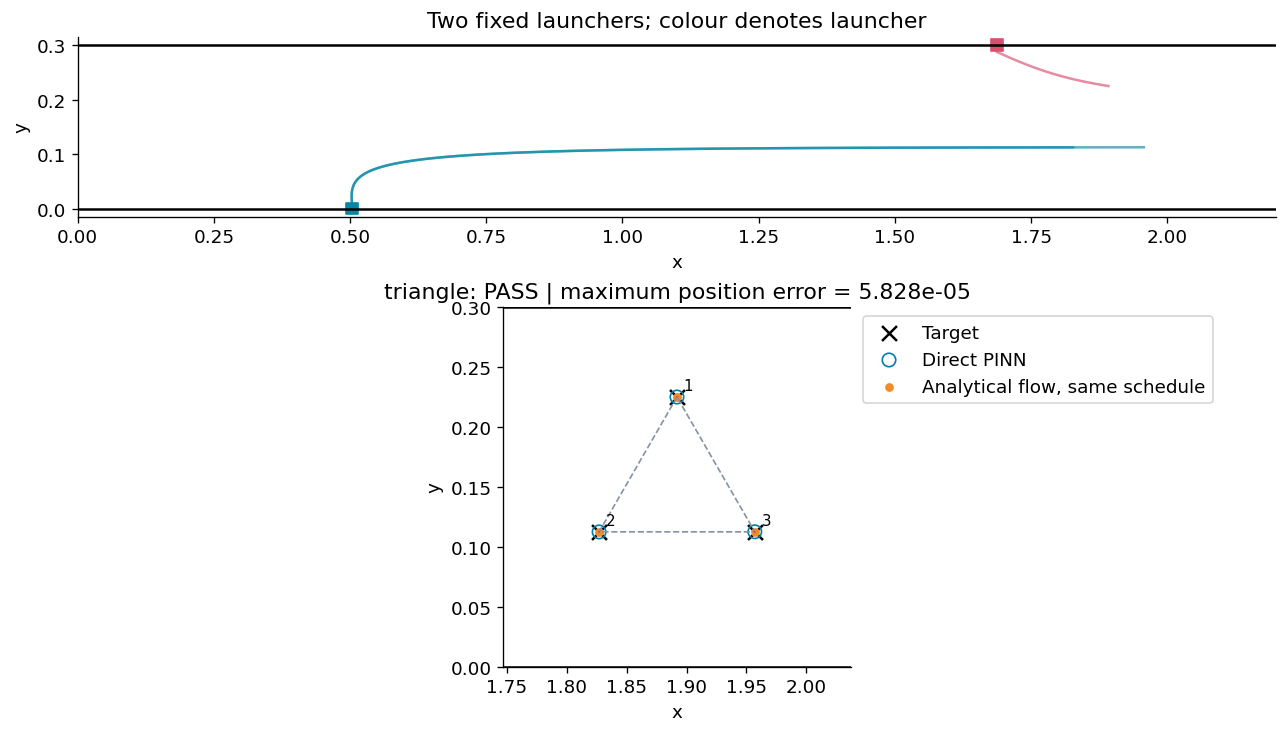

/kaggle/working/rectangular_wall_launchers_1793526873435880082/formations/triangle/replay.html

{"kind": "triangle", "success": true, "reason": "all numerical checks passed", "max_error": 5.827744906741368e-05, "min_pair_distance": 0.03174763006047407, "max_reference_error": 0.00016951057312002021}

Optimizing: square
square start 1: lookup max error=0.00010182, min separation=0.034744
square start 2: lookup max error=8.0613e-05, min separation=0.025733
square start 3: lookup max error=0.010346, min separation=0.024805


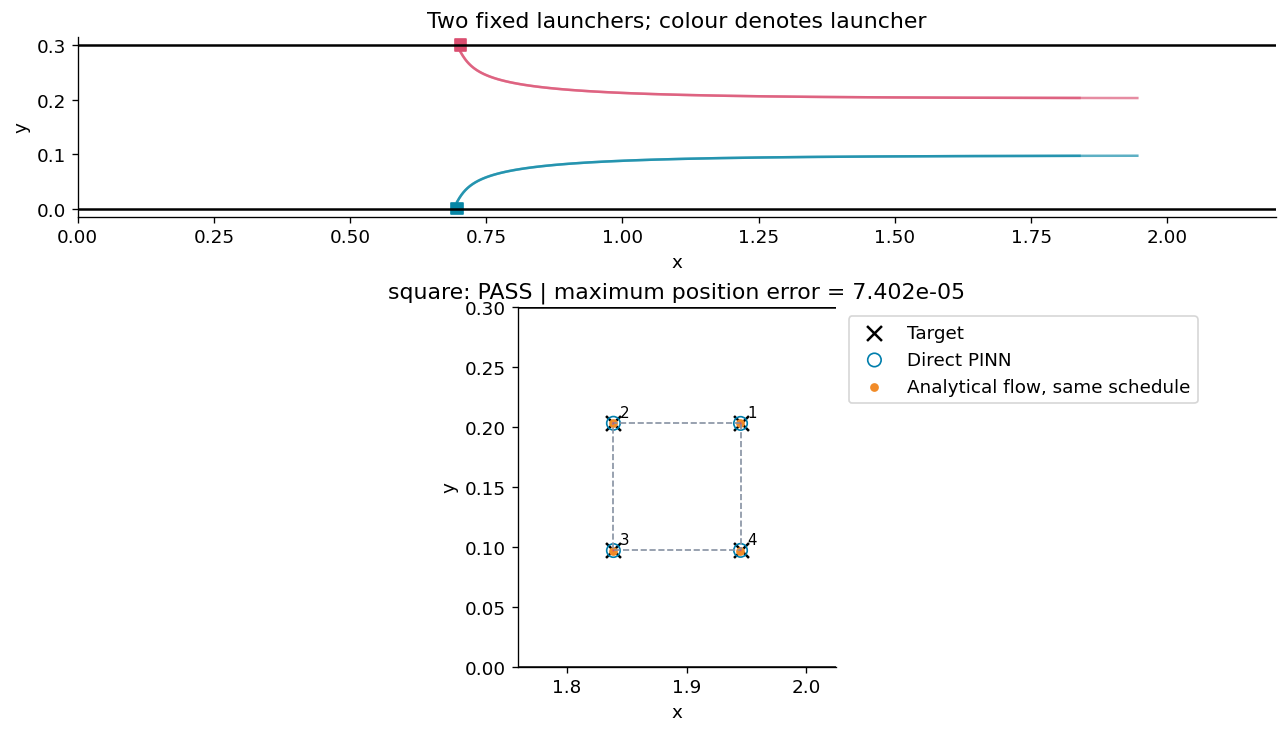

/kaggle/working/rectangular_wall_launchers_1793526873435880082/formations/square/replay.html

{"kind": "square", "success": true, "reason": "all numerical checks passed", "max_error": 7.40201533397645e-05, "min_pair_distance": 0.031990379027550135, "max_reference_error": 0.0008416581205806273}

Optimizing: circle_10
circle_10 start 1: lookup max error=0.03214, min separation=0.025915
circle_10 start 2: lookup max error=0.036648, min separation=0.02099
circle_10 start 3: lookup max error=0.027392, min separation=0.025715


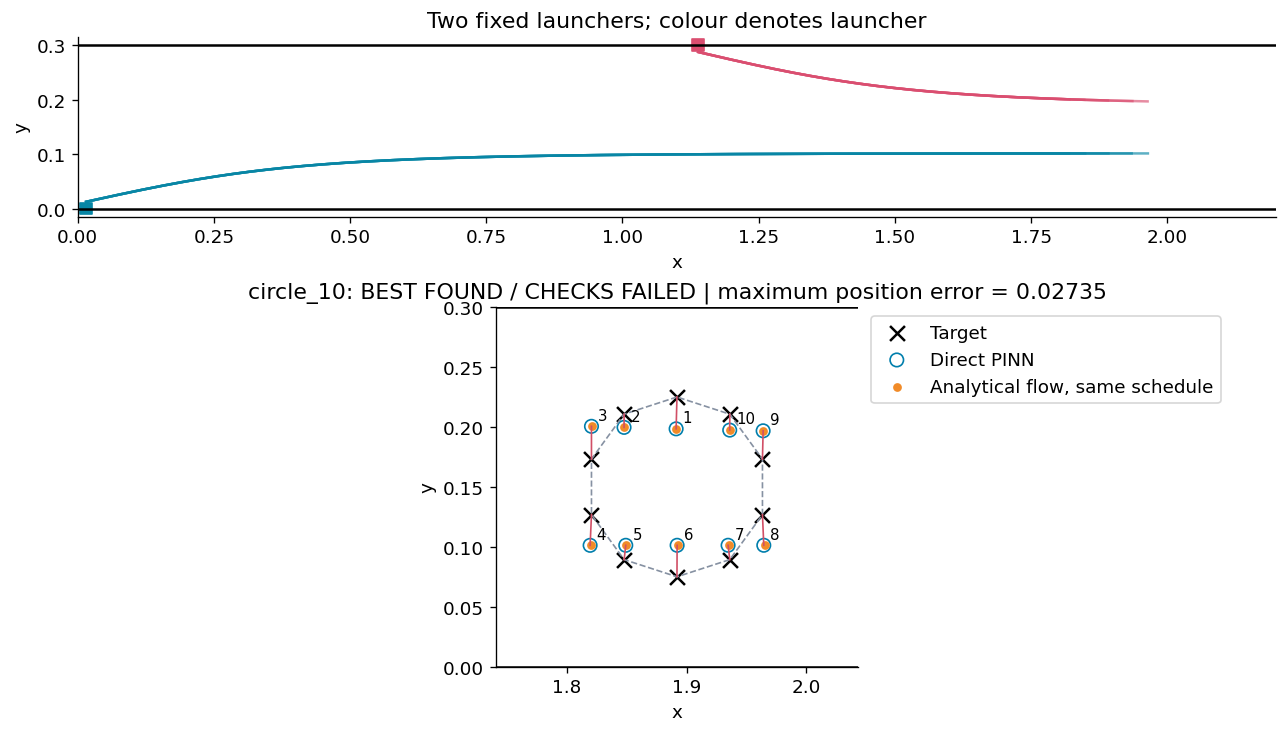

/kaggle/working/rectangular_wall_launchers_1793526873435880082/formations/circle_10/replay.html

{"kind": "circle_10", "success": false, "reason": "target tolerance missed or trajectory ended before target time; particle clearance failed; analytical-flow cross-check failed", "max_error": 0.027353989311334873, "min_pair_distance": 0.02572350531154204, "max_reference_error": 0.027428925627314485}

Optimizing: s_8
s_8 start 1: lookup max error=0.054361, min separation=0.025058
s_8 start 2: lookup max error=0.043866, min separation=0.025226
s_8 start 3: lookup max error=0.053785, min separation=0.025417


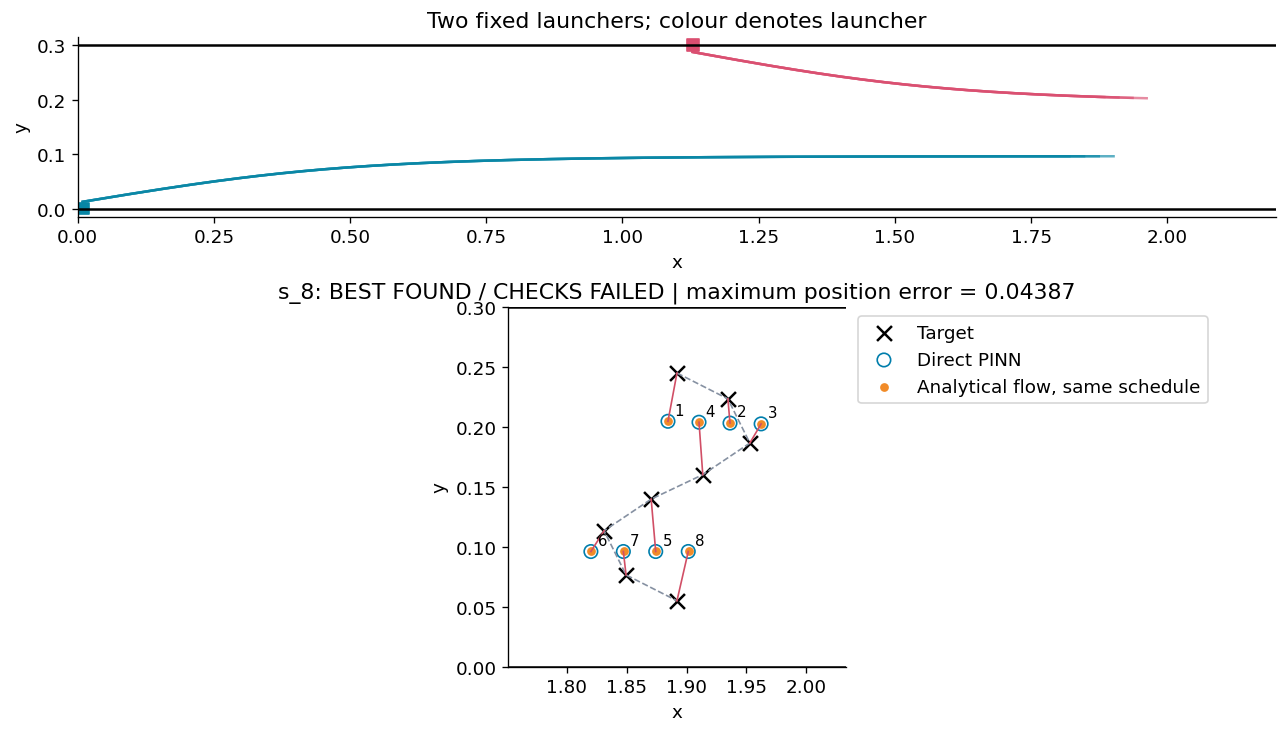

/kaggle/working/rectangular_wall_launchers_1793526873435880082/formations/s_8/replay.html

{"kind": "s_8", "success": false, "reason": "target tolerance missed or trajectory ended before target time; particle clearance failed; analytical-flow cross-check failed", "max_error": 0.04387088895552221, "min_pair_distance": 0.025230617570569314, "max_reference_error": 0.043934255417007774}

Optimizing: chevron_7
chevron_7 start 1: lookup max error=0.0010617, min separation=0.049345
chevron_7 start 2: lookup max error=0.0010617, min separation=0.049345
chevron_7 start 3: lookup max error=0.037444, min separation=0.025727


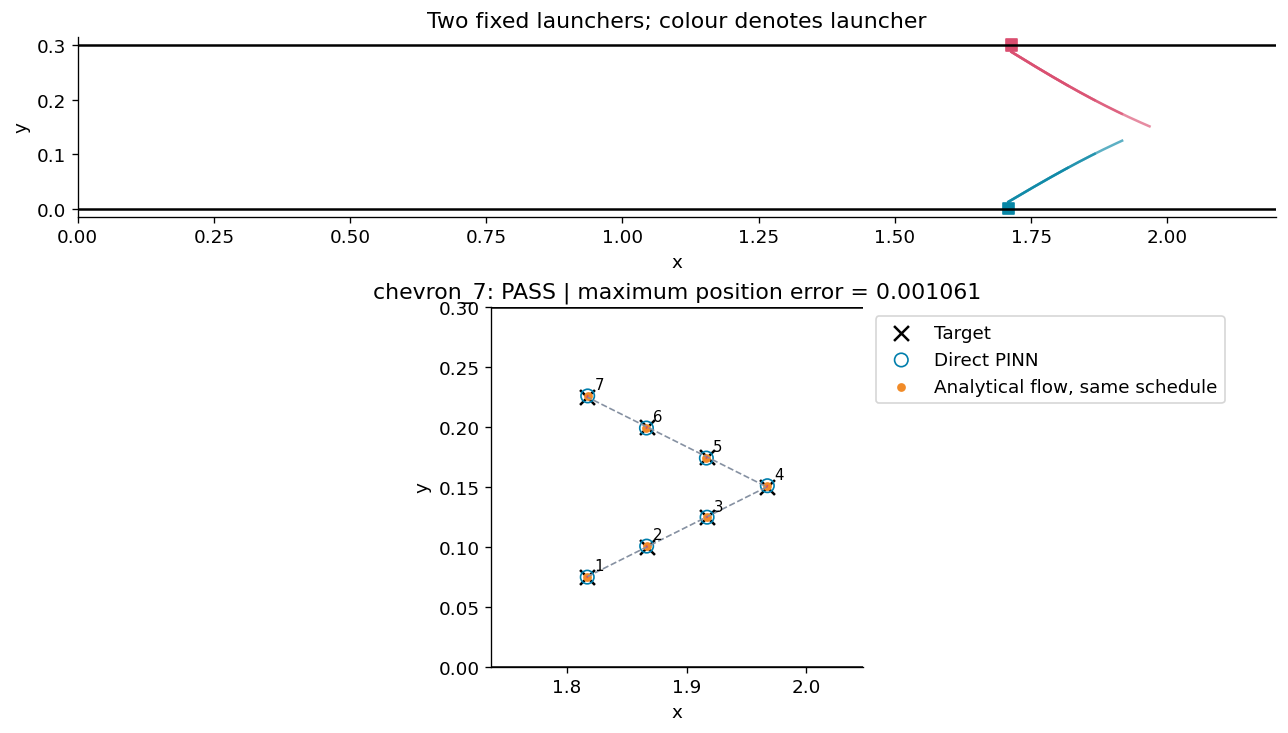

/kaggle/working/rectangular_wall_launchers_1793526873435880082/formations/chevron_7/replay.html

{"kind": "chevron_7", "success": true, "reason": "all numerical checks passed", "max_error": 0.0010612763556725074, "min_pair_distance": 0.04934506109551275, "max_reference_error": 0.001066028365304835}


In [10]:
def write_schedule(path, rows):
    if not rows: return
    with path.open('w', newline='', encoding='utf-8') as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)


def plot_formation(result, directory):
    if 'actual' not in result: return
    target, actual = np.array(result['targets']), np.array(result['actual'])
    reference = np.array(result['analytical_reference'])
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), layout='constrained',
                             gridspec_kw={'height_ratios': [1, 2]})
    ax = axes[0]
    for trajectory in result['paths']:
        xy = np.array(trajectory['states'])[:, :2]
        ax.plot(xy[:, 0], xy[:, 1], color=['#0786a5', '#da4e70'][trajectory['side']], alpha=.65)
    c = result['shared_controls']
    ax.scatter([c['x_bottom'], c['x_top']], [0, H], marker='s', s=50, color=['#0786a5', '#da4e70'])
    for a in axes: a.axhline(0, color='k'); a.axhline(H, color='k'); a.set(xlabel='x', ylabel='y', aspect='equal')
    ax.set(xlim=(0, L), ylim=(-.015, H+.015), title='Two fixed launchers; colour denotes launcher')
    ax = axes[1]
    order = np.r_[np.arange(len(target)), 0] if result['closed'] else np.arange(len(target))
    ax.plot(target[order, 0], target[order, 1], '--', color='#8691a2', linewidth=1)
    ax.scatter(target[:, 0], target[:, 1], marker='x', s=80, color='black', label='Target')
    ax.scatter(actual[:, 0], actual[:, 1], s=65, facecolors='none', edgecolors='#007eac', label='Direct PINN')
    ax.scatter(reference[:, 0], reference[:, 1], s=18, color='#f18b28', label='Analytical flow, same schedule')
    for i, (a, b) in enumerate(zip(target, actual)):
        ax.plot([a[0], b[0]], [a[1], b[1]], color='#d14f66', linewidth=1)
        ax.annotate(str(i+1), b, xytext=(4, 4), textcoords='offset points', fontsize=9)
    ax.set(xlim=(max(0, target[:, 0].min()-.08), min(L, target[:, 0].max()+.08)),
           ylim=(0, H), title=f'{result["kind"]}: {"PASS" if result["success"] else "BEST FOUND / CHECKS FAILED"}'
           f' | maximum position error = {result["max_error"]:.4g}')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    fig.savefig(directory/'formation.png', dpi=240)
    plt.show()


def write_formation_animation(result, path):
    # Includes actual release times. Curves are dense direct-PINN ODE samples.
    data = dict(result=result, L=L, H=H, diameter=DIAMETER)
    template = r'''<!doctype html><html><meta charset="utf-8"><title>Formation replay</title>
<style>body{font:16px system-ui;background:#112036;color:#e6f1ff;margin:30px auto;max-width:1150px;padding:16px}canvas{width:100%;background:#edf6fc;border-radius:12px}input{width:75%}button{padding:8px 18px;margin:10px;border-radius:7px;border:0;background:#7ae1cc}pre{white-space:pre-wrap;color:#bacce3}</style>
<h2 id="title"></h2><p id="verdict"></p><canvas id="canvas" width="1400" height="380"></canvas>
<button id="play">Play / pause</button><input id="time" type="range" min="0" step="0.001"><output id="clock"></output>
<p>Replay includes emission timing from the same two fixed launchers. Target shape appears near the outlet at the final instant.</p>
<pre id="details"></pre><script>const D=__DATA__,R=D.result,c=document.getElementById('canvas'),ctx=c.getContext('2d'),s=(c.width-100)/D.L,oy=(c.height+D.H*s)/2;
let slider=document.getElementById('time'),playing=false,last=0;slider.max=R.target_time;
const map=(x,y)=>[50+x*s,oy-y*s];
function state(p,age){let a=p.ages,z=p.states;if(age<a[0]||age>a[a.length-1])return null;let l=0,h=a.length-1;while(h-l>1){let m=(h+l)>>1;if(a[m]<age)l=m;else h=m}let f=(age-a[l])/(a[h]-a[l]||1);return [z[l][0]*(1-f)+z[h][0]*f,z[l][1]*(1-f)+z[h][1]*f]}
function draw(){let t=+slider.value;ctx.clearRect(0,0,c.width,c.height);ctx.strokeStyle='#324d6a';ctx.lineWidth=3;for(let y of [0,D.H]){ctx.beginPath();ctx.moveTo(...map(0,y));ctx.lineTo(...map(D.L,y));ctx.stroke()}
ctx.strokeStyle='#9cabc1';ctx.lineWidth=1;ctx.setLineDash([5,5]);ctx.beginPath();R.targets.forEach((p,i)=>{i?ctx.lineTo(...map(...p)):ctx.moveTo(...map(...p))});if(R.closed)ctx.closePath();ctx.stroke();ctx.setLineDash([]);
R.targets.forEach(p=>{let [x,y]=map(...p);ctx.beginPath();ctx.moveTo(x-4,y-4);ctx.lineTo(x+4,y+4);ctx.moveTo(x-4,y+4);ctx.lineTo(x+4,y-4);ctx.stroke()});
for(let p of R.paths){ctx.strokeStyle=p.side?'#da4e70':'#0786a5';ctx.globalAlpha=.2;ctx.beginPath();p.states.forEach((z,i)=>{i?ctx.lineTo(...map(z[0],z[1])):ctx.moveTo(...map(z[0],z[1]))});ctx.stroke();ctx.globalAlpha=1;let q=state(p,t-p.release);if(q){ctx.fillStyle=ctx.strokeStyle;ctx.beginPath();ctx.arc(...map(...q),D.diameter*s/2,0,2*Math.PI);ctx.fill()}}
let C=R.shared_controls;[[C.x_bottom,0],[C.x_top,D.H]].forEach((p,i)=>{ctx.fillStyle=i?'#da4e70':'#0786a5';let [x,y]=map(...p);ctx.fillRect(x-7,y-7,14,14)});document.getElementById('clock').textContent=t.toFixed(3)+' / '+R.target_time.toFixed(3)}
document.getElementById('title').textContent=R.kind;document.getElementById('verdict').textContent=(R.success?'PASS':'BEST FOUND — CHECKS FAILED')+': '+R.reason;
document.getElementById('details').textContent=JSON.stringify({shared_controls:R.shared_controls,max_error:R.max_error,min_pair_distance:R.min_pair_distance,target_time:R.target_time},null,2);
slider.oninput=draw;document.getElementById('play').onclick=()=>{if(+slider.value>=R.target_time)slider.value=0;playing=!playing};
function tick(ts){if(playing){slider.value=Math.min(R.target_time,+slider.value+Math.min((ts-last)/1000,.05)*R.target_time/12);if(+slider.value>=R.target_time)playing=false;draw()}last=ts;requestAnimationFrame(tick)}draw();requestAnimationFrame(tick);</script></html>'''
    path.write_text(template.replace('__DATA__', json.dumps(data)), encoding='utf-8')


FORMATION_RESULTS = []
if RUN_OPTIMIZATION:
    if not VALIDATION['passed'] and not ALLOW_UNVALIDATED_OPTIMIZATION:
        raise RuntimeError('Flow validation failed. Inspect validation.json, increase training '
            'and rerun validation before optimizing. Exploratory override is in settings; '
            'overridden runs can never be labelled successful.')
    # Freeze all neural weights. Optimization changes controls and release ages only.
    model.eval().requires_grad_(False)
    lookup = FlowLookup(model)
    test_xy = np.random.default_rng(SEED+421).uniform([0, 0], [L, H], (2000, 2))
    lookup_error = float(np.max(np.abs(lookup(test_xy)-direct_field(test_xy, CONTROL_MID))))
    (RUN/'lookup_validation.json').write_text(json.dumps(dict(
        max_velocity_interpolation_error=lookup_error, controls=CONTROL_MID.tolist(),
        note='Search acceleration only. All final trajectories use the full 8-input PINN.'), indent=2))
    coarse = SharedLauncherPlanner(lookup, 'lookup')
    direct = SharedLauncherPlanner(direct_field, 'direct PINN', rtol=ODE_RTOL,
                                  atol=ODE_ATOL, max_step=TRAJECTORY_MAX_STEP)
    bank = scout_bank(coarse)
    for kind in SHAPES:
        directory = RUN/'formations'/kind
        directory.mkdir(parents=True, exist_ok=True)
        print('\nOptimizing:', kind, flush=True)
        try:
            result = plan_formation(kind, coarse, direct, bank)
        except (RuntimeError, ValueError, FloatingPointError) as exc:
            result = dict(kind=kind, success=False, reason=str(exc))
        FORMATION_RESULTS.append(result)
        (directory/'result.json').write_text(json.dumps(result, indent=2))
        if 'schedules' in result:
            write_schedule(directory/'release_schedule.csv', result['schedules'])
            write_schedule(directory/'shared_launcher_controls.csv', [result['shared_controls']])
            flat = []
            for trajectory in result['paths']:
                for age, state in zip(trajectory['ages'], trajectory['states']):
                    flat.append(dict(particle=trajectory['particle'], side=trajectory['side'],
                        time=age+trajectory['release'], age=age, x=state[0], y=state[1],
                        u=state[2], v=state[3]))
            write_schedule(directory/'trajectories.csv', flat)
            write_formation_animation(result, directory/'replay.html')
            plot_formation(result, directory)
            display(FileLink(str(directory/'replay.html')))
        print(json.dumps({key: result[key] for key in
            ['kind', 'success', 'reason', 'max_error', 'min_pair_distance', 'max_reference_error']
            if key in result}), flush=True)
        # Persist after each experiment so a later interruption loses no earlier results.
        (RUN/'formation_summary.json').write_text(json.dumps([
            {key: val for key, val in r.items() if key not in ['paths', 'schedules']}
            for r in FORMATION_RESULTS], indent=2))
    summary_rows = [{key: r.get(key) for key in ['kind', 'success', 'max_error',
        'rms_error', 'min_pair_distance', 'max_reference_error', 'reason']} for r in FORMATION_RESULTS]
    write_schedule(RUN/'formation_summary.csv', summary_rows)
else:
    print('Optimization skipped by RUN_OPTIMIZATION=False.')


## ۱۱. دریافت خروجی‌ها
بستهٔ ZIP شامل بهترین وزن، تنظیمات، روند آموزش، اعتبارسنجی تحلیلی، نمایشگر پرتابگرها و نتایج شکل‌ها است. برای هر شکل، کنترل‌های مشترک، جدول زمان رهاسازی، مسیرها، خطاها، تصویر و انیمیشن HTML ذخیره می‌شوند. بعد از آموزش می‌توانید تنظیمات آزمایش‌ها را تغییر دهید و سلول‌های ۸ تا ۱۱ را دوباره اجرا کنید؛ تا زمانی که از بازهٔ کنترل و ثابت‌های فیزیکی خارج نشده‌اید، آموزش دوباره لازم نیست.

In [11]:
# Re-run this cell whenever you want a fresh bundle of the current results.
notes = f'''Rectangular channel with two wall launchers
Flow-network inputs: {', '.join(INPUT_NAMES)}
Flow-network outputs: u, v, p
Geometry: 0<=x<={L}, 0<=y<={H}; centreline velocity {U_C}
Fixed Re={RE}; d={DIAMETER}; rho_p/rho_f={DENSITY_RATIO}
Full position ranges: x_bottom,x_top in [0,{L}]
Coupling: one-way; no fluid source flux, feedback or particle contact forces.
Particle law: spherical point-particle drag, {DRAG_LAW}; no gravity, buoyancy,
lift, added mass, history force, deformation or coalescence.
Default density ratio is the previous rigid-particle setting, NOT a gas bubble.
Changing density alone does not establish a physically complete bubble model.
Particles start one radius+gap inside the walls at virtual injection ports.
Formation: six shared launch controls per experiment, one side and release time
per particle. Shapes form at one time inside the channel near the outlet.
They are not claimed to remain rigid, or to exist as 2D shapes on line x=L.
Best-found searches do not establish global feasibility or optimality.
PASS requires independent flow validation, direct PINN position tolerance,
strict ODE re-integration, analytical-flow comparison, and pair-clearance checks.
Collision checks are numerical sampling plus local refinement, not a proof.
See config.json, validation.json and each formation's result.json for evidence.
'''
(RUN/'README.txt').write_text(notes)
archive = shutil.make_archive(str(RUN), 'zip', root_dir=RUN)
print('Results, checkpoints, diagnostics, schedules and offline viewers:')
display(FileLink(archive))
print('Offline launcher viewer:')
display(FileLink(str(VIEWER_PATH)))
print('Flow validated:', VALIDATION['passed'], '| formation passes:',
      sum(bool(r.get('success')) for r in FORMATION_RESULTS), '/', len(FORMATION_RESULTS))


Results, checkpoints, diagnostics, schedules and offline viewers:


/kaggle/working/rectangular_wall_launchers_1793526873435880082.zip

Offline launcher viewer:


/kaggle/working/rectangular_wall_launchers_1793526873435880082/wall_launchers_viewer.html

Flow validated: True | formation passes: 3 / 5
